# French air traffic network: how centralised on Paris-CDG, and how fragile?

Graph analytics project, Albert School (2026). Data: DGAC, *Trafic aérien commercial mensuel français par paire d'aéroports* (data.gouv.fr, Licence Ouverte 2.0).

**Main message.** France's published air network is a hub-and-spoke system around CDG: robust to random failures, fragile to the loss of CDG. The centralisation is an *international* phenomenon (domestically, the network is spread out, with two Paris hubs: Orly carries the most passengers, CDG has the most routes), it is what a hub with CDG's number of routes produces anyway (null model), and it has been stable for 35 years.

This notebook only calls the functions in `src/` (one module per task) and follows the order of the defence:

1. Data and graph model
2. What the network looks like (core metrics)
3. Centrality: CDG in a league of its own
4. Two networks in one: international vs domestic
5. Is it surprising? Degree-preserving null model
6. Resilience: robust yet fragile
7. Communities
8. Comparison over time (2019 / 2020 / 2025, and 1990-2025)
9. Robustness of the conclusions and limitations
10. Conclusion

Appendix: exploratory work (passenger-loss metrics, bipartite projection).

The scripts in `src/` write the tables to `results/` (`python src/<module>.py`); the notebook recomputes them and displays the report figures saved in `results/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
RESULTS = ROOT / "results"

import matplotlib
matplotlib.use("Agg")
import networkx as nx
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.width", 200, "display.max_colwidth", 80, "display.precision", 3)

YEAR = 2025
N_NULL = 500                # random graphs per view in the null model (500 ~ 45 s)
REGENERATE_FIGURES = False  # True: redraw every figure in results/ (fonts may differ by machine)

def show(name, width=950):
    display(Image(filename=str(RESULTS / f"{name}.png"), width=width))

## 1. Data and graph model

- **Nodes**: airports (ICAO codes), French (metropolitan and overseas) and foreign.
- **Edges**: one undirected edge per airport pair with published traffic in the year (monthly rows summed). DGAC publishes both directions of a route in one row, so the graph is undirected and simple.
- **Weights**: annual passengers (`weight="passengers"`) for strength-type measures and Louvain; `cost = 1/passengers` for weighted shortest paths. Distances are otherwise counted in hops (number of flights).

**Limitation to keep in mind.** DGAC only publishes a route-month with at least 10,000 passenger-equivalents, at least 3 airlines and no airline above 85 % of the traffic. Routes run by one or two airlines are missing, and only flights touching France are covered: there are no foreign-foreign routes, so the network is star-shaped by construction around French airports.

In [2]:
from build_graph import build_graph, build_graphs, summary

G = build_graph(YEAR)
pd.DataFrame({y: summary(g) for y, g in build_graphs((2019, 2020, 2025)).items()})

,2019,2020,2025
year,2019,2020,2025
nodes,137,107,151
french_nodes,27,24,31
foreign_nodes,110,83,120
edges,293,183,289
directed,False,False,False
multigraph,False,False,False
connected,False,False,False
components,2,3,3
component_sizes,"[135, 2]","[103, 2, 2]","[147, 2, 2]"


## 2. What the network looks like (core metrics)

In [3]:
import core_metrics

core = core_metrics.run(YEAR)
keys = ["nodes", "nodes_french_metro", "nodes_french_overseas", "nodes_foreign", "edges", "density",
        "degree_mean", "degree_median", "degree_max", "leaves", "leaves_share", "components",
        "lcc_nodes", "lcc_share", "diameter", "radius", "center", "avg_shortest_path",
        "articulation_points", "bridges", "core_bridges"]
pd.Series({k: core["summary"][k] for k in keys}, name=YEAR).to_frame()

,2025
nodes,151
nodes_french_metro,22
nodes_french_overseas,9
nodes_foreign,120
edges,289
density,0.026
degree_mean,3.828
degree_median,1.0
degree_max,99
leaves,78


In [4]:
display(core["components"])
core["articulation_points"].head(6)

,component,nodes,edges,passengers,airports
0,0,147,287,73396400,147 airports incl. LFPG
1,1,2,1,66994,"LFOB (BEAUVAIS-TILLE), LUKK (CHISINAU)"
2,2,2,1,113211,"TFFJ (ST-BARTHELEMY), TNCM (ST-MARTIN JULIANA)"


,icao,name,zone,degree,components_after,new_components,cut_off
0,LFPG,PARIS-CHARLES DE GAULLE,metro,99,53,51,55
1,LFPO,PARIS-ORLY,metro,34,9,7,6
2,KLAX,LOS ANGELES INTL,foreign,2,4,2,5
3,NTAA,TAHITI FAA'A,overseas,5,7,5,4
4,EGSS,LONDRES-STANSTED,foreign,4,5,3,2
5,LFSB,BALE-MULHOUSE,metro,20,5,3,2


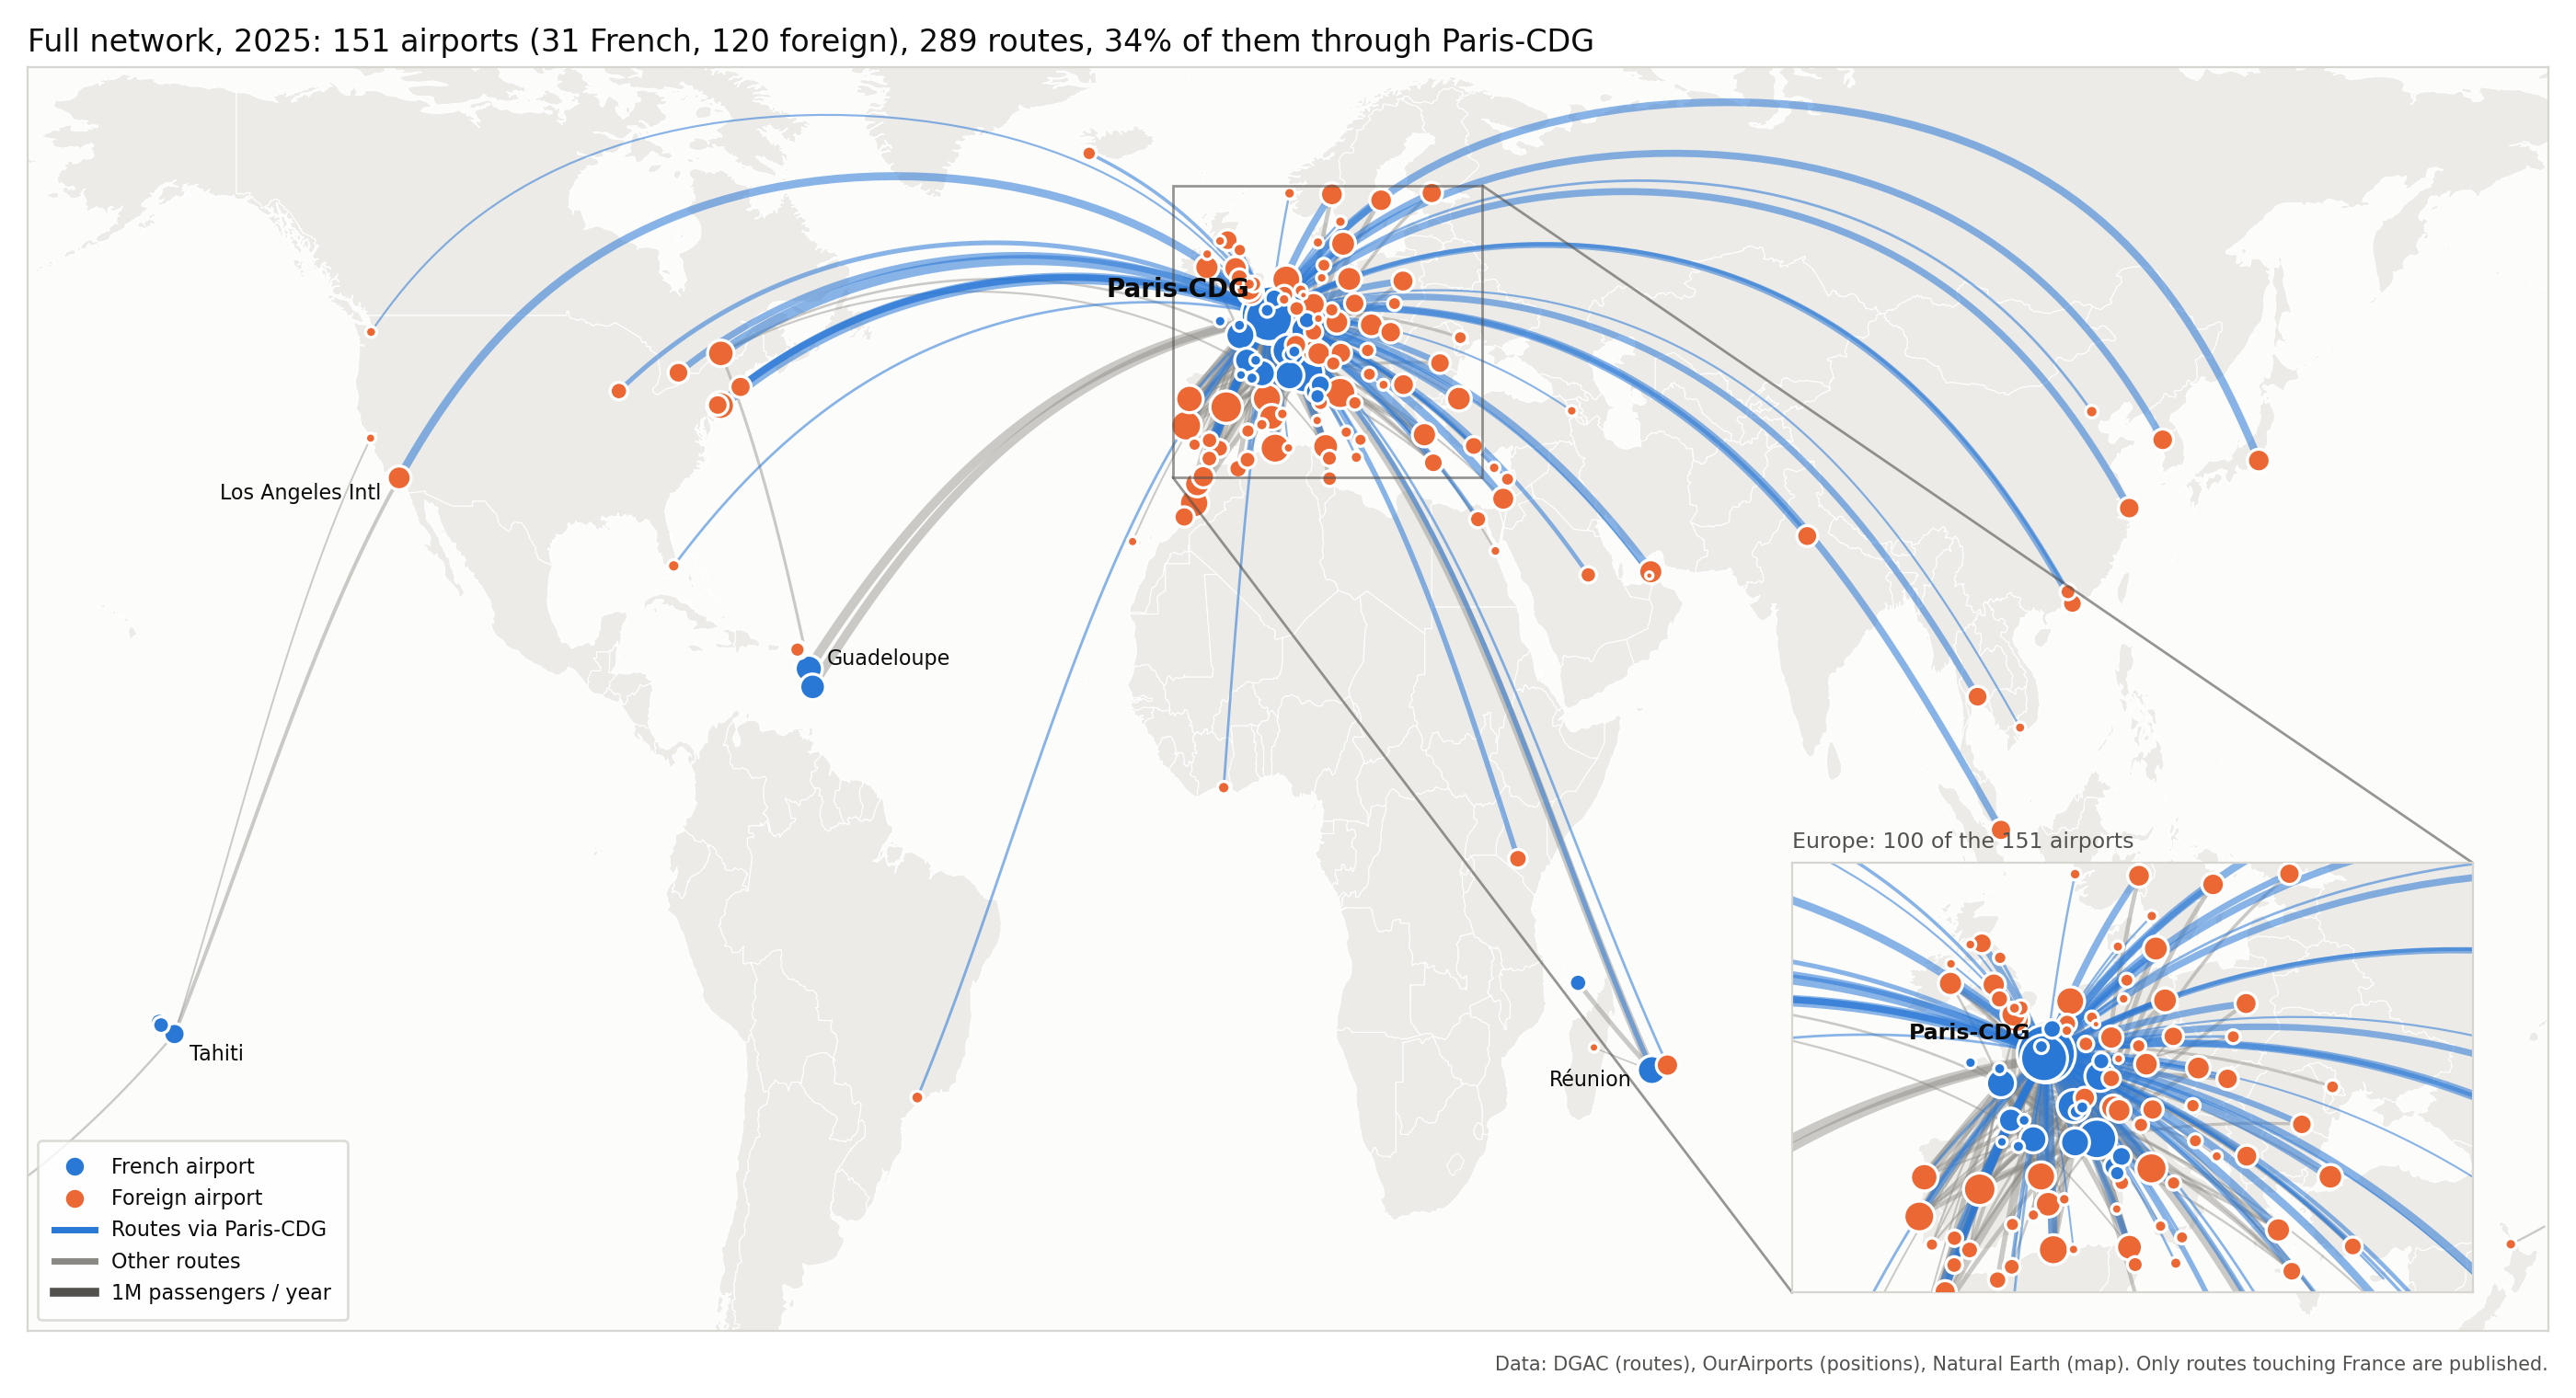

In [5]:
show('map_full_2025')

151 airports and 289 routes, but a very sparse graph (density 0.026): the median airport has **one** route and more than half of the airports are leaves, mostly foreign airports linked only to CDG. The largest component holds 147 airports, its diameter is 6 hops, its radius 3, and its **centre is CDG alone**. CDG is also by far the worst articulation point: removing it cuts 55 airports off the main component.

## 3. Centrality: CDG in a league of its own

In [6]:
import centrality

cent = centrality.run(YEAR)
display(pd.Series(cent["centralization"], name="Freeman centralization").to_frame())
cent["focus"][["name", "degree", "strength", "betweenness", "harmonic", "pagerank",
               "degree_vs_cdg", "strength_vs_cdg", "betweenness_vs_cdg"]]

,Freeman centralization
degree_centralization,0.643
betweenness_centralization,0.702


,name,degree,strength,betweenness,harmonic,pagerank,degree_vs_cdg,strength_vs_cdg,betweenness_vs_cdg
icao,,,,,,,,,
LFPG,PARIS-CHARLES DE GAULLE,99,38808298,0.708,0.794,0.239,1.000,1.000,1.000
LFPO,PARIS-ORLY,34,16011171,0.138,0.510,0.083,0.343,0.413,0.195
LFMN,NICE-COTE D'AZUR,36,7963910,0.138,0.590,0.046,0.364,0.205,0.195
LFLL,LYON-ST-EXUPERY,31,3760656,0.056,0.473,0.024,0.313,0.097,0.079
KLAX,LOS ANGELES INTL,2,922189,0.063,0.438,0.007,0.020,0.024,0.089
NTAA,TAHITI FAA'A,5,553253,0.051,0.319,0.012,0.051,0.014,0.073
LFSB,BALE-MULHOUSE,20,2653583,0.049,0.519,0.017,0.202,0.068,0.070
LFML,MARSEILLE-PROVENCE,14,2130239,0.039,0.496,0.014,0.141,0.055,0.055
LFRS,NANTES-ATLANTIQUE,21,2140752,0.034,0.456,0.014,0.212,0.055,0.048


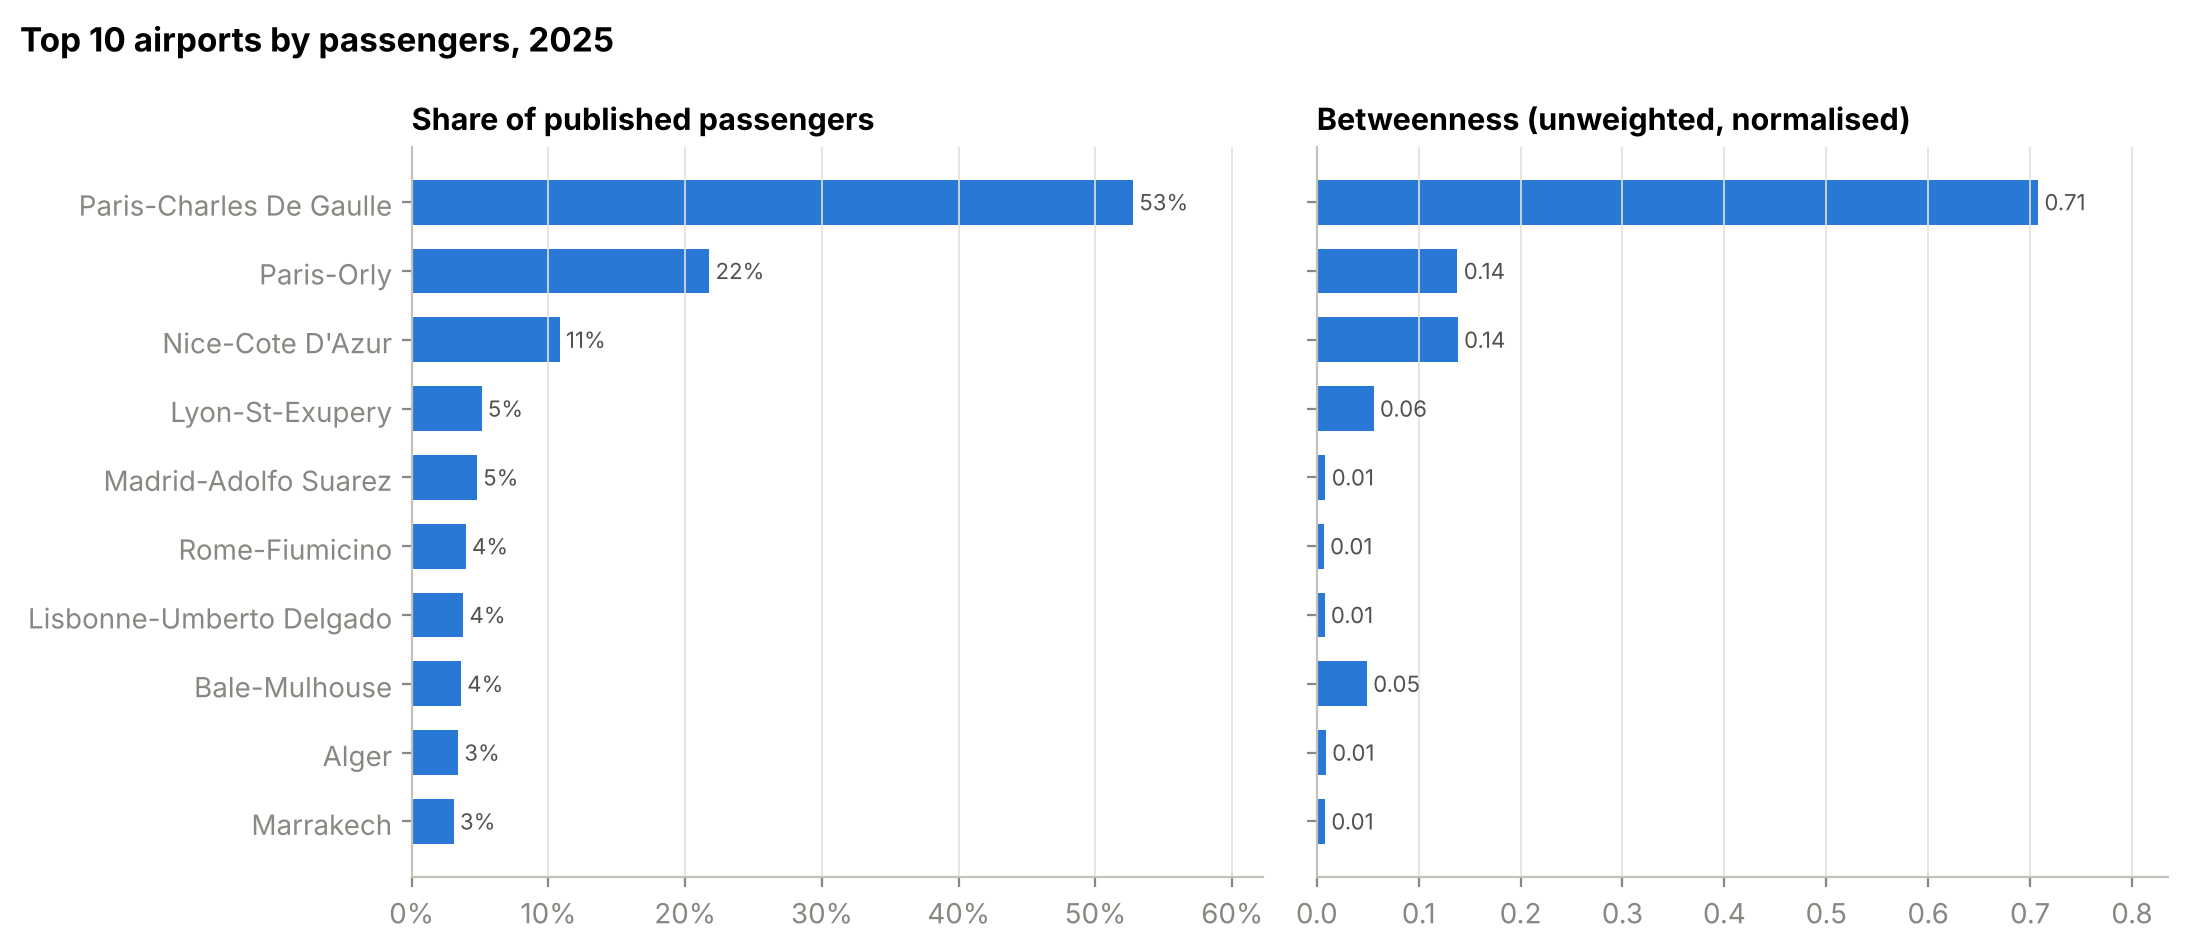

In [7]:
show('centrality_2025')

In [8]:
display(Markdown("**Robustness: CDG's betweenness with and without single-route foreign airports**"))
display(cent["robustness"])
display(Markdown("**Gateways: airports whose betweenness rank is much higher than their degree rank**"))
cent["gateways"].head(5)

**Robustness: CDG's betweenness with and without single-route foreign airports**

,variant,nodes,edges,cdg_betweenness,top_others,degree_centralization,betweenness_centralization
0,full graph,151,289,0.708,"LFMN 0.14, LFPO 0.14, KLAX 0.06",0.643,0.702
1,without single-route foreign airports,84,222,0.441,"LFMN 0.20, LFPO 0.14, LFLL 0.10",0.552,0.429
2,French airports only,31,40,0.065,"LFPO 0.16, LFMN 0.13, LFML 0.11",0.193,0.142


**Gateways: airports whose betweenness rank is much higher than their degree rank**

,name,zone,degree,rank_degree,betweenness,rank_betweenness,rank_gap
icao,,,,,,,
NTAA,TAHITI FAA'A,overseas,5,19,0.051,6,13
LFKF,FIGARI-SUD-CORSE,metro,4,25,0.015,14,11
TFFR,GUADELOUPE-MARYSE CONDE,overseas,4,25,0.014,15,10
FMEE,LA REUNION-ROLAND GARROS,overseas,5,19,0.030,10,9
LFMN,NICE-COTE D'AZUR,metro,36,2,0.138,2,0


CDG has 99 routes (one route in three; 2 of them are cargo routes with almost no passengers, see section 9), 53 % of the published passengers and a betweenness of 0.71; Nice and Orly follow at 0.14, five times lower. All centrality measures agree on the top of the ranking (Spearman correlations in `results/centrality_spearman_2025.csv`).

Part of CDG's betweenness comes from the many foreign airports that only connect to it: without single-route foreign airports it drops to 0.44, still more than twice the next airport. Some small airports matter more than their degree suggests: Tahiti, Réunion, Figari and Guadeloupe are bridges to overseas territories and Corsica.

## 4. Two networks in one: international vs domestic

In [9]:
import views

vw = views.run(YEAR)
display(vw["comparison"])
pd.Series(vw["intl_summary"], name="international").to_frame()

view,full network,domestic
nodes,151,31
edges,289,40
density,0.026,0.086
components,3,8
isolated_airports,0,6
lcc_nodes,147,22
diameter_lcc,6,5
radius_lcc,3,3
center_lcc,LFPG,"LFBO, LFKB, LFMN, LFPO"
avg_shortest_path_lcc,2.602,2.485


,international
international_routes,249.000
foreign_destinations,120.000
cdg_passenger_share,0.591
destinations_only_via_cdg,49.000


In [10]:
display(vw["domestic_centrality"].head(8)[["name", "degree", "strength", "betweenness", "harmonic", "pagerank"]])
vw["domestic_resilience"]

,name,degree,strength,betweenness,harmonic,pagerank
icao,,,,,,
LFPO,PARIS-ORLY,6,5288867,0.163,0.428,0.162
LFMN,NICE-COTE D'AZUR,8,3291484,0.130,0.456,0.117
LFML,MARSEILLE-PROVENCE,7,1041832,0.106,0.431,0.066
LFLL,LYON-ST-EXUPERY,7,862634,0.067,0.411,0.051
LFPG,PARIS-CHARLES DE GAULLE,5,1680131,0.065,0.403,0.065
FMEE,LA REUNION-ROLAND GARROS,3,1449232,0.052,0.342,0.050
TFFR,GUADELOUPE-MARYSE CONDE,3,1583177,0.046,0.311,0.052
LFKB,BASTIA-PORETTA,3,404512,0.045,0.372,0.025


,removed,components,isolated,lcc_nodes,lcc_share_of_airports,passengers_kept_in_lcc
0,none,8,6,22,0.710,0.962
1,CDG,8,6,21,0.677,0.805
2,Orly,9,6,18,0.581,0.423
3,CDG + Orly,10,6,15,0.484,0.247


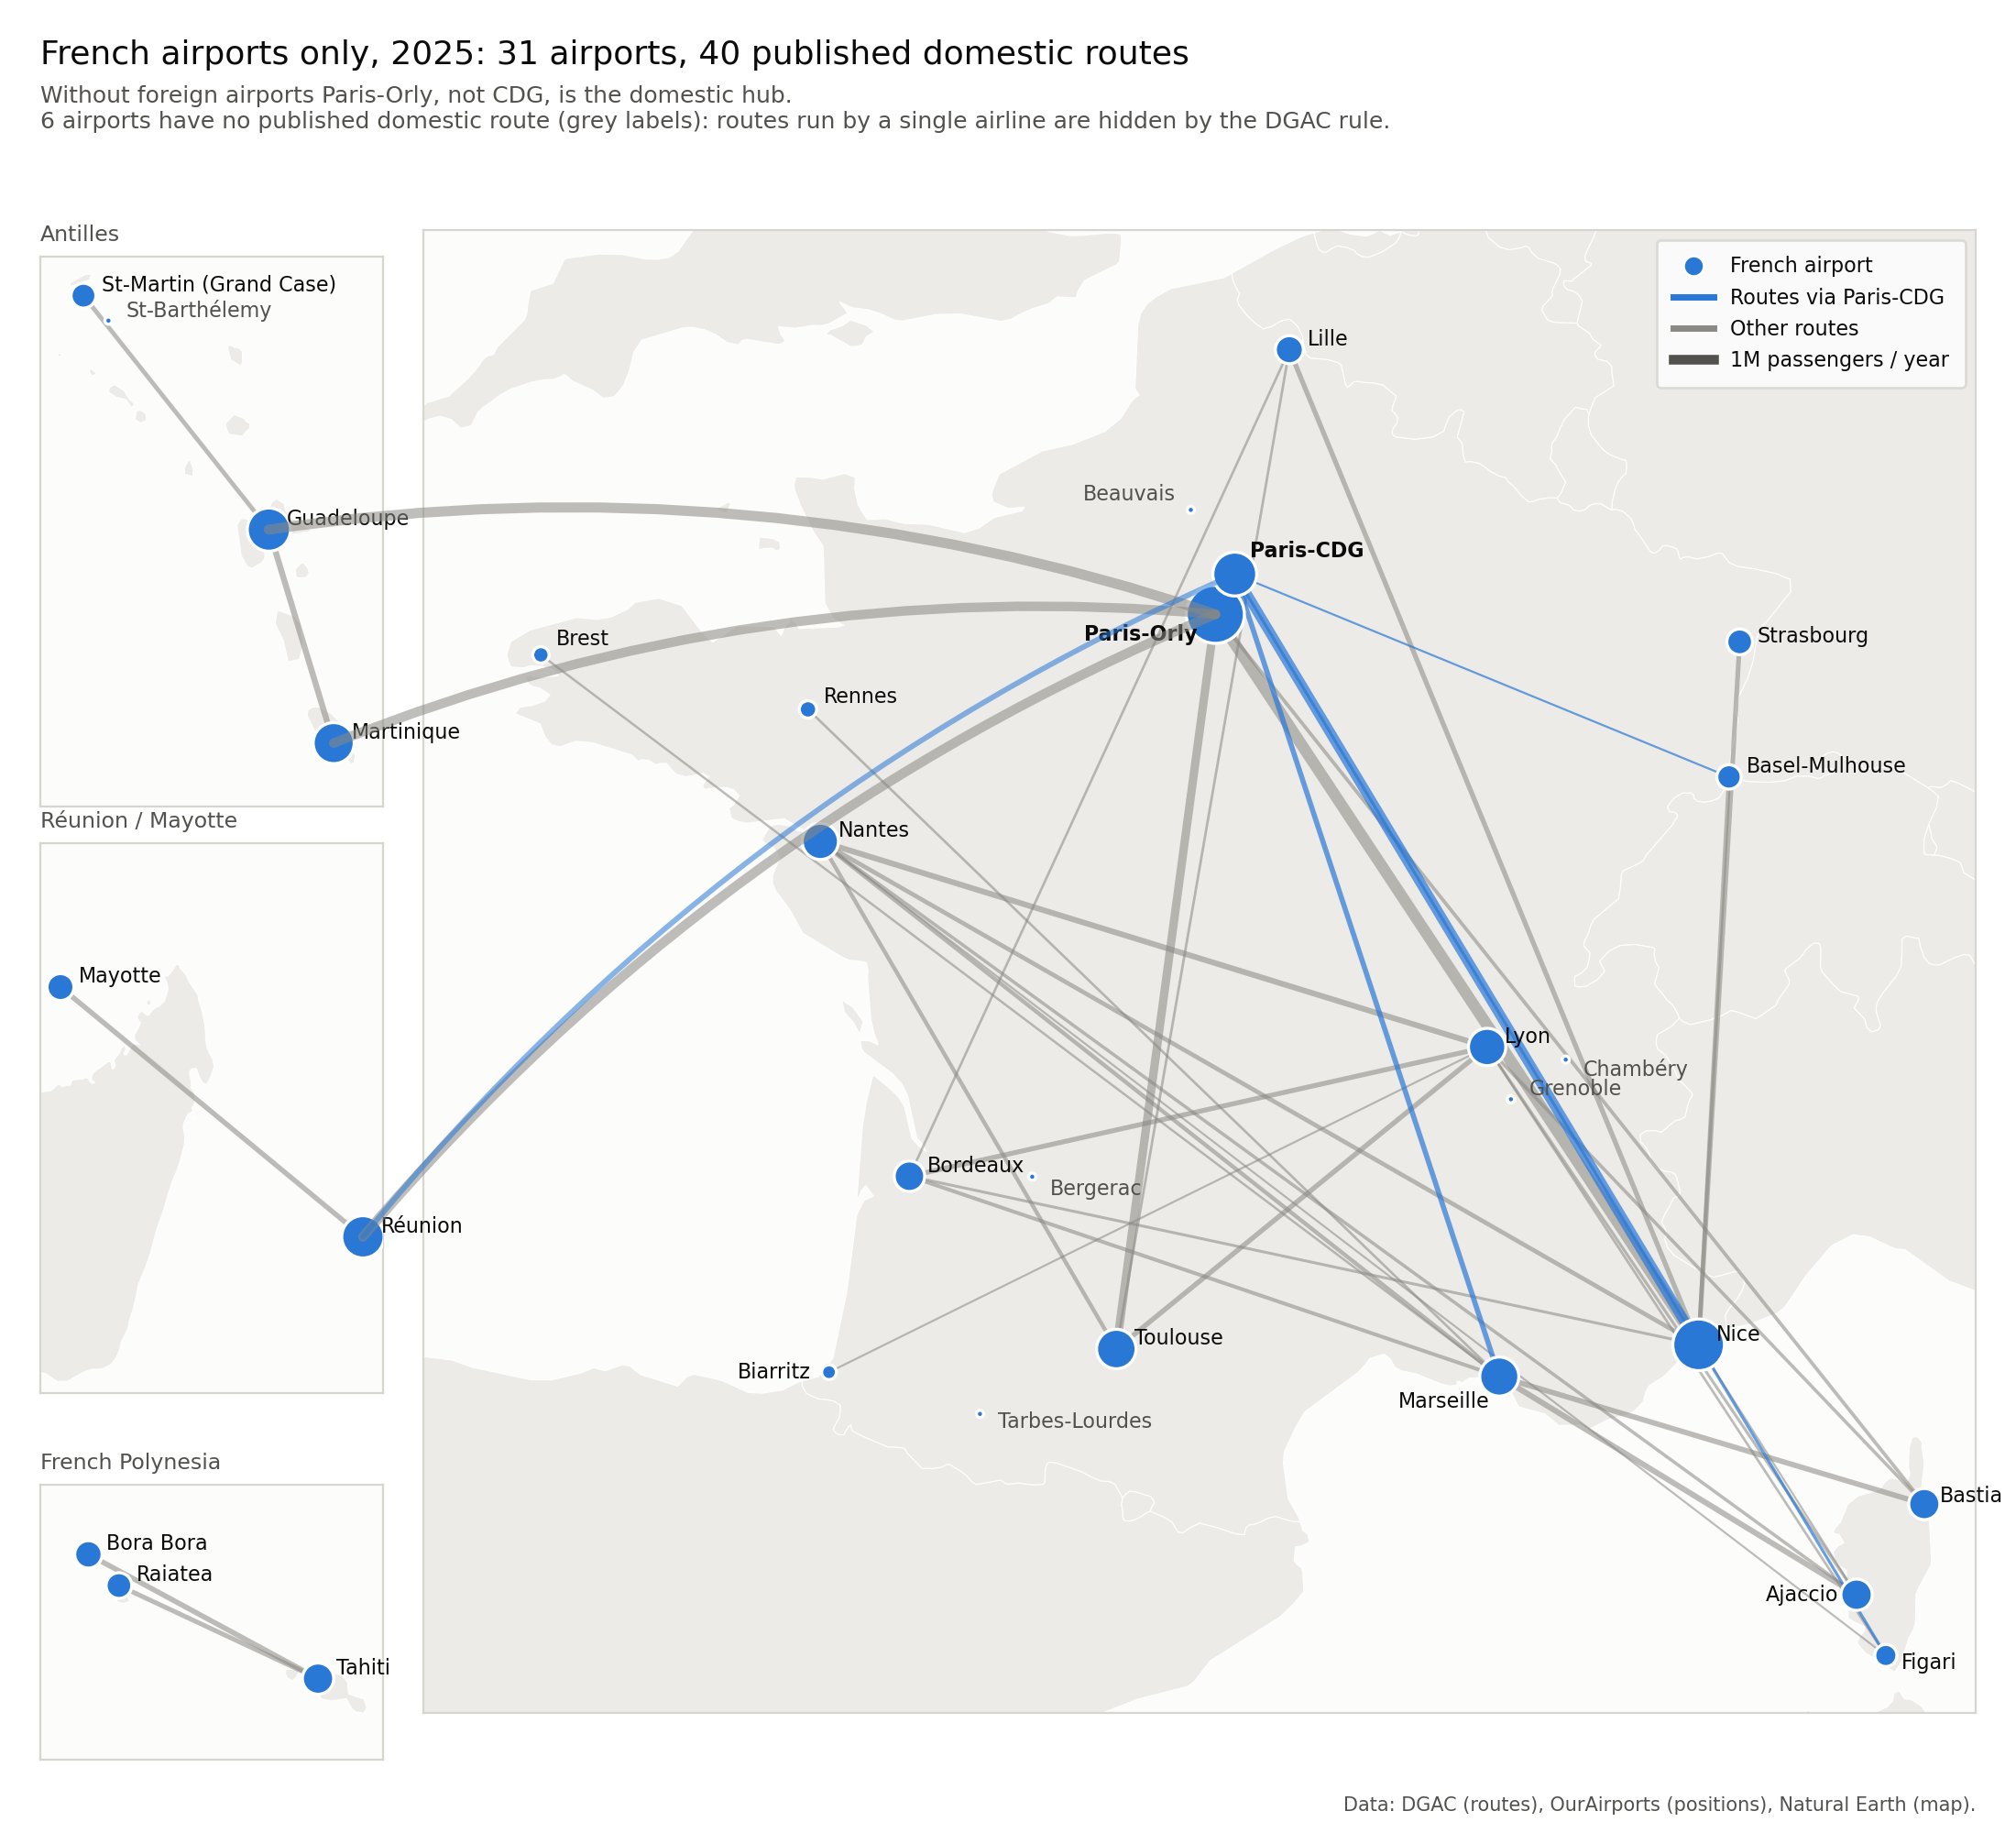

In [11]:
show('map_french_2025')

The centralisation on CDG is an **international** phenomenon. CDG carries 59 % of the international passengers and **49 foreign destinations are reachable only through CDG**. On the published domestic network (French airports only), CDG has 5 routes and ranks 5th in betweenness and Orly looks like the domestic hub, and the domestic network is far less centralised (betweenness centralisation 0.14 vs 0.70). Domestically, losing Orly is worse than losing CDG (42 % vs 80 % of domestic passengers kept in the main component).

But the published domestic network is very incomplete (40 routes; major routes such as Lyon-CDG, Toulouse-CDG or Marseille-Orly are missing), so we check these domestic conclusions against a second source.

### 4b. Completing the domestic network with Eurostat

Eurostat publishes every route of the main French airports (dataset `avia_par_fr`, passengers carried), without the DGAC 3-airline rule. Annual data stop at 2024, so the check is made on 2024 (and 2019, 2020), comparing the complete Eurostat domestic network with the DGAC published domestic network of the same year.

In [12]:
import domestic_eurostat

dom_summary, dom_hidden = domestic_eurostat.run()
display(dom_summary.set_index(["year", "source"]).T)
dom_hidden[dom_hidden["year"] == 2024].head(10)[["route", "passengers"]]

year                                                              2019                                                                                    2020  \
source                                           Eurostat (all routes)                     DGAC (published routes)                       Eurostat (all routes)   
airports                                                            39                                          25                                          31   
routes                                                             134                                          56                                         118   
passengers_m                                                    30.749                                       16.39                                      12.999   
components                                                           1                                           1                                           1   
betweenness_centralization                                       0.384                                       0.379                                       0.287   
top_betweenness             LFPO 0.41, LFPG 0.18, LFKF 0.11, LFML 0.11  LFPO 0.43, LFPG 0.22, LFMN 0.21, LFBO 0.14  LFPO 0.31, LFPG 0.27, TFFR 0.13, SOCA 0.07   
top_routes                          LFPO 25, LFPG 20, LFLL 19, LFML 17           LFPG 11, LFLL 10, LFRS 10, LFMN 9          LFPO 21, LFPG 20, LFLL 17, LFML 15   
top_passengers_m               LFPO 13.6, LFPG 6.8, LFMN 4.9, LFBO 4.8      LFPO 6.9, LFBO 3.7, LFPG 3.7, LFMN 3.6      LFPO 5.4, LFPG 2.9, LFBO 1.9, LFMN 1.7   
cdg_routes                                                          20                                          11                                          20   
orly_routes                                                         25                                           7                                          21   
cdg_betweenness_rank                                                 2                                           2                                           2   
orly_betweenness_rank                                                1                                           1                                           1   
cdg_passengers_m                                                 6.794                                       3.711                                       2.886   
orly_passengers_m                                               13.611                                        6.92                                        5.39   
kept_without_cdg                                                 0.779                                       0.774                                       0.778   
kept_without_orly                                                0.557                                       0.548                                       0.585   

year                                                                                                          2024                                              
source                                         DGAC (published routes)                       Eurostat (all routes)                     DGAC (published routes)  
airports                                                            21                                          37                                          25  
routes                                                              40                                         128                                          38  
passengers_m                                                     5.311                                       24.48                                      10.411  
components                                                           1                                           1                                           1  
betweenness_centralization                                       0.413                                        0.24   

,route,passengers
160,PARIS-CHARLES DE GAULLE - TOULOUSE-BLAGNAC,786606.5
161,PARIS-CHARLES DE GAULLE - BORDEAUX-MERIGNAC,628681.0
162,PARIS-CHARLES DE GAULLE - LYON-ST-EXUPERY,558808.5
163,PARIS-ORLY - AJACCIO-NAPOLEON-BONAPARTE,485095.5
164,PARIS-ORLY - BASTIA-PORETTA,468261.5
165,PARIS-CHARLES DE GAULLE - NANTES-ATLANTIQUE,434367.5
166,PARIS-CHARLES DE GAULLE - MONTPELLIER-MEDITERRANEE,427511.0
167,MARSEILLE-PROVENCE - PARIS-ORLY,379982.5
168,PARIS-CHARLES DE GAULLE - BREST-BRETAGNE,325871.5
169,PARIS-CHARLES DE GAULLE - GUADELOUPE-MARYSE CONDE,265193.0


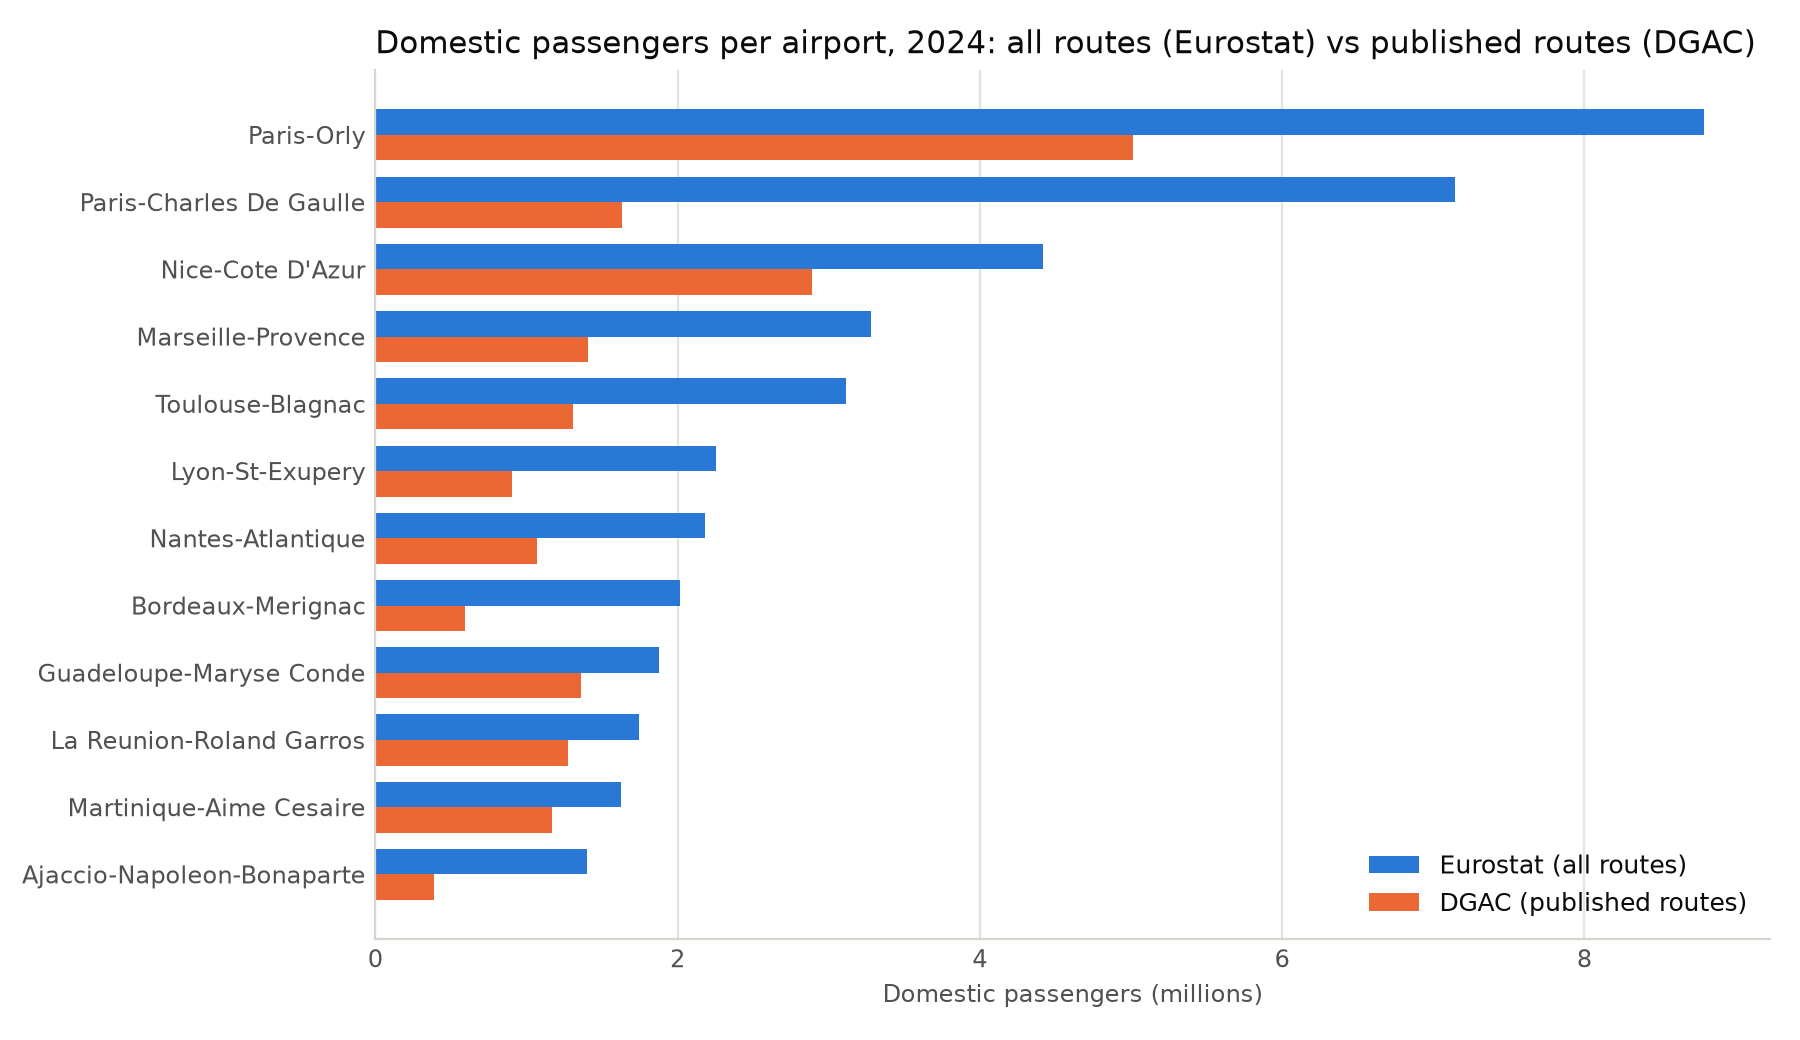

In [13]:
show('domestic_eurostat_2024', width=800)

In 2024 the complete domestic network has **128 routes and 24.5 M passengers**, against 38 routes and 10.4 M in the DGAC published data. The biggest hidden routes are single-airline routes: CDG's feeder routes to the regions (Toulouse, Bordeaux, Lyon, Nantes, Montpellier: 0.4 to 0.8 M passengers each), Orly-Corsica and Marseille-Orly.

What changes once they are added back:
- **Paris has two domestic hubs.** CDG has the most domestic routes (19) and the highest betweenness (0.27, Orly 0.23); Orly carries the most domestic passengers (8.8 M vs 7.1 M for CDG). The published data hid most of CDG's domestic traffic (1.6 M published). "Orly is *the* domestic hub" is therefore too strong: Orly is the volume hub, CDG the connecting hub, consistent with CDG feeding its long-haul flights.
- **Losing Orly still hurts more**: 64 % of domestic passengers stay in the main component without Orly, 71 % without CDG (DGAC data: 49 % vs 81 %).
- **The domestic network stays decentralised**: betweenness centralisation 0.24 (DGAC: 0.26), far below the 0.70 of the full network. The international vs domestic contrast of section 4 holds.

## 5. Is it surprising? Degree-preserving null model

Random graphs that keep every airport's number of routes (double-edge swaps, never creating a foreign-foreign route, which the data cannot contain). For each metric: real value, mean and standard deviation over the random graphs, z-score and empirical p-value.

In [14]:
import null_model

null_table, null_samples = null_model.run(YEAR, N_NULL)
null_table

,view,metric,real,null_mean,null_sd,z,p_two_sided
0,full network,cdg_betweenness,0.708,0.692,0.017,0.931,0.360
1,full network,orly_betweenness,0.138,0.130,0.019,0.398,0.704
2,full network,betweenness_centralization,0.702,0.687,0.017,0.921,0.360
3,full network,degree_assortativity,-0.460,-0.430,0.005,-6.451,0.000
4,full network,hub_density_top10,0.511,0.604,0.043,-2.147,0.056
5,full network,modularity_louvain,0.398,0.383,0.005,2.676,0.036
6,full network,communities,8.000,8.254,1.121,-0.227,1.000
7,full network,components,3.000,1.642,0.789,1.720,0.268
8,full network,avg_shortest_path_lcc,2.602,2.488,0.026,4.417,0.004
9,full network,diameter_lcc,6.000,5.204,0.572,1.392,0.508


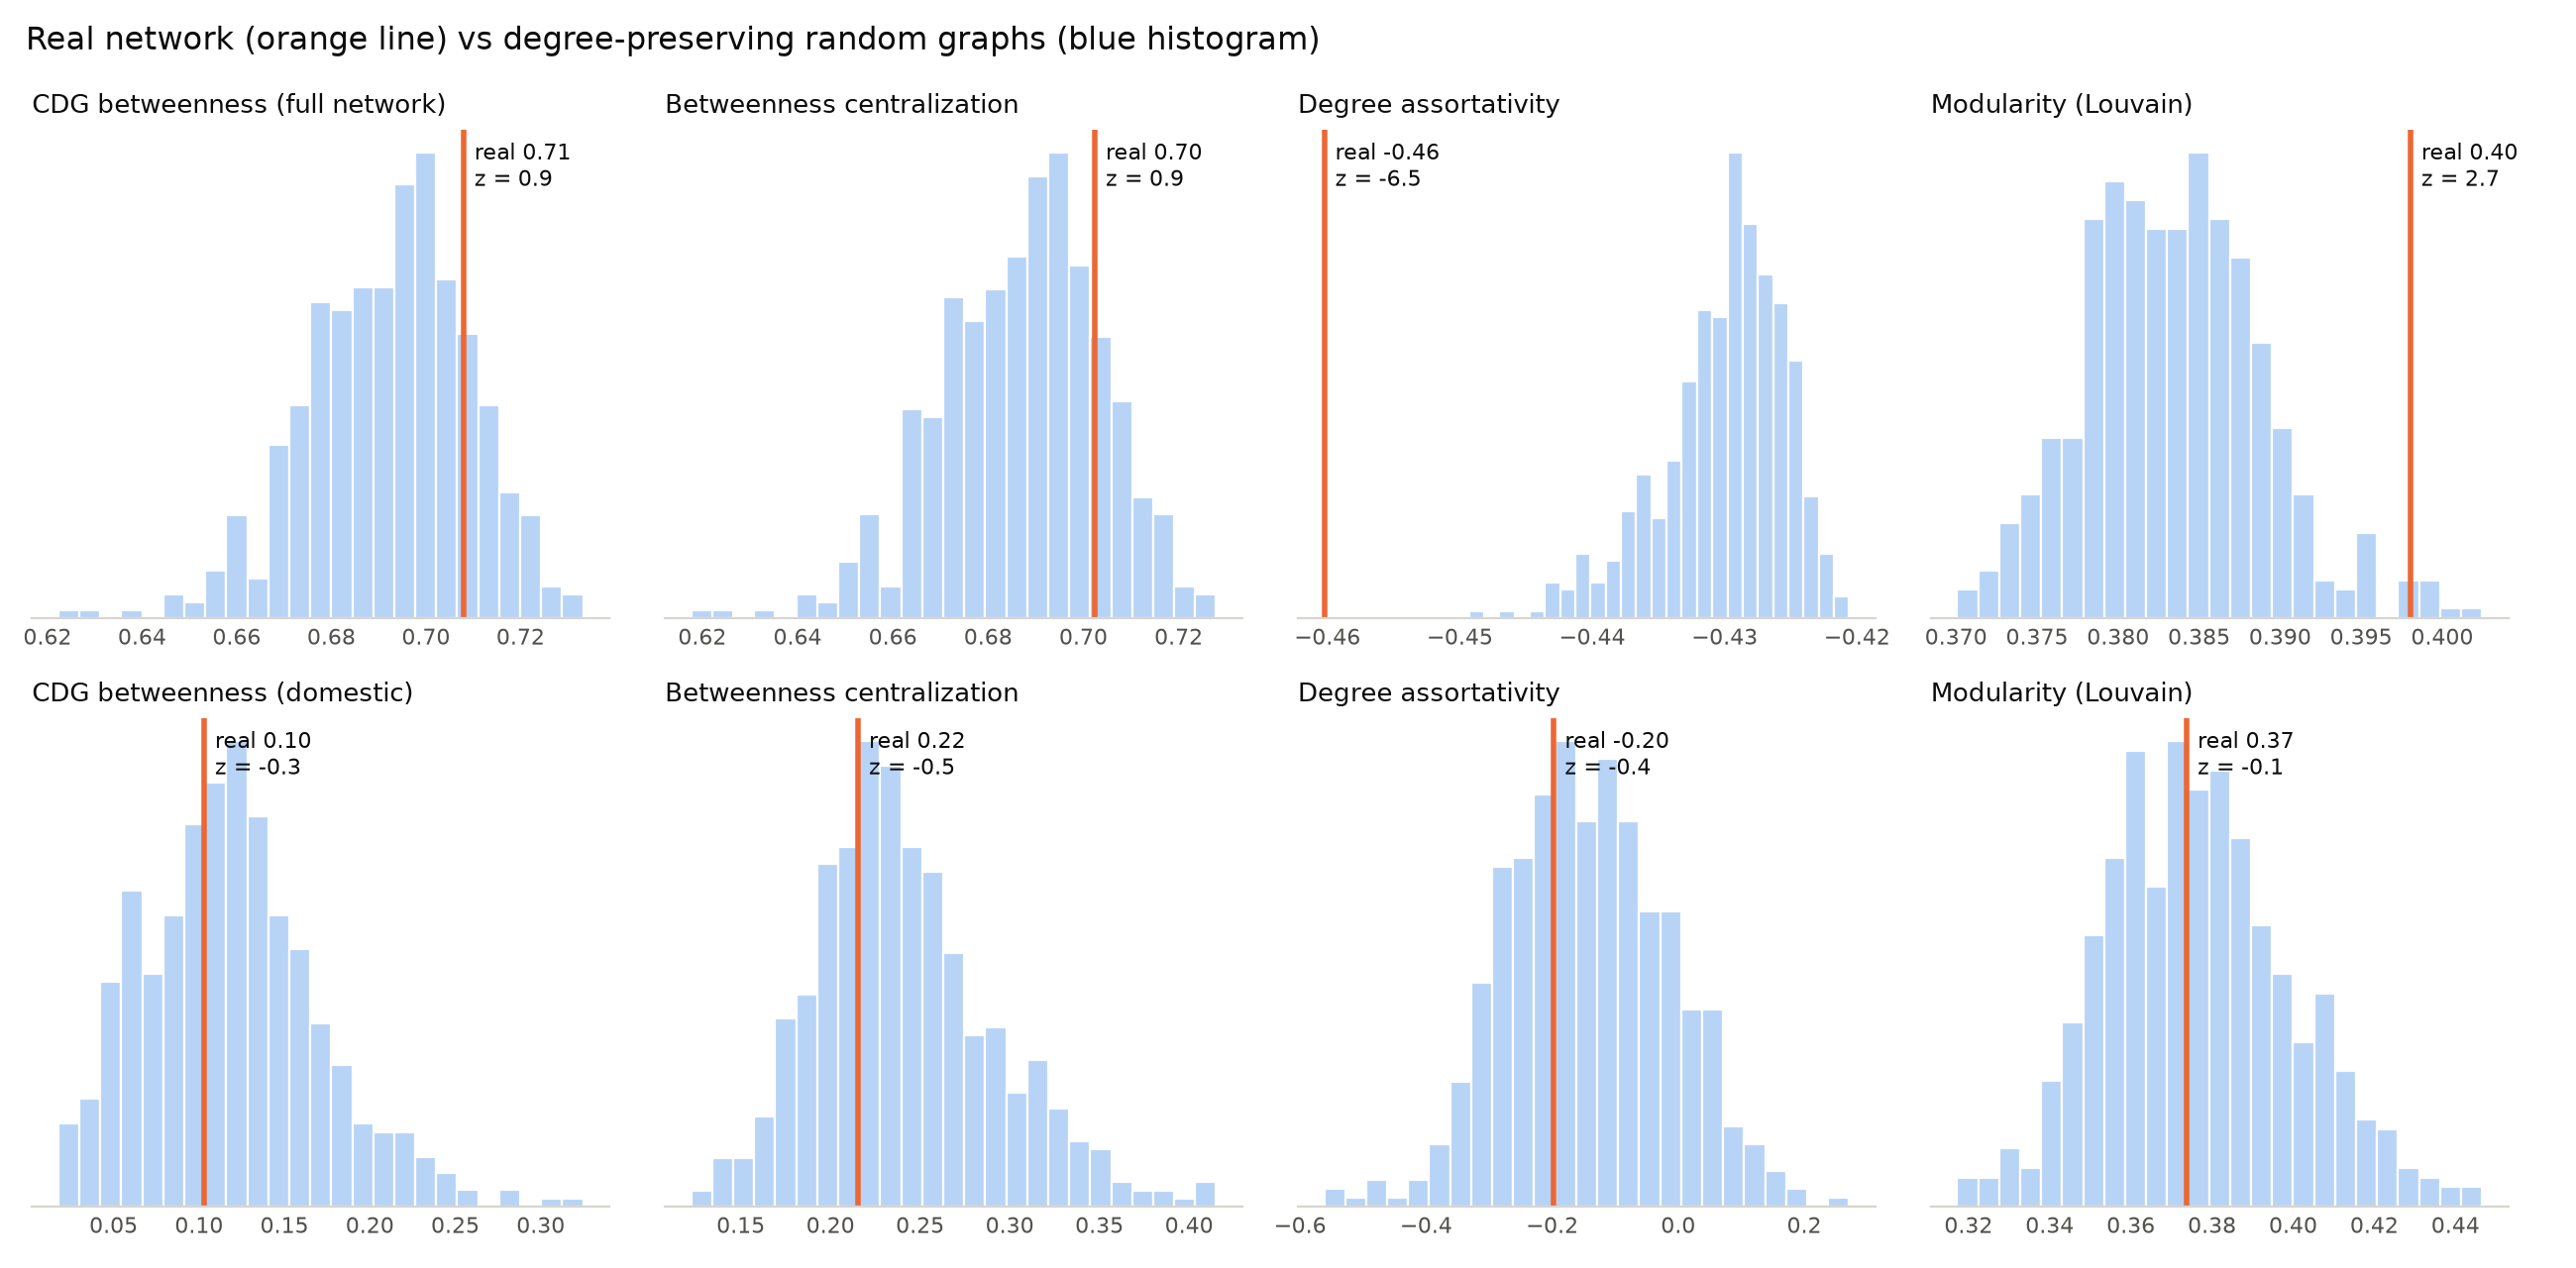

In [15]:
show('null_model_2025')

CDG's betweenness (0.71) is what a hub with 99 routes gets in random graphs with the same degrees (0.69 on average, p = 0.36): **CDG's dominance is explained by its number of routes**, not by a particular wiring. What the wiring adds is a strongly disassortative, hub-and-spoke structure (assortativity -0.46 vs -0.43, z = -6.5) and slightly more community structure than chance (modularity p = 0.04). On the domestic network nothing differs significantly from chance.

## 6. Resilience: robust yet fragile

Airports are removed and the remaining graph is measured: fixed scenarios (CDG, Orly, CDG + Orly) against random removals of the same size, and removal curves (targeted by degree, passengers or betweenness, against random failures, mean of 100 orders).

In [16]:
import resilience

scen = resilience.scenarios(G)
scen[["scenario", "removed", "lcc_share", "isolated", "french_pairs_connected", "passengers_kept", "lcc_diameter"]]

,scenario,removed,lcc_share,isolated,french_pairs_connected,passengers_kept,lcc_diameter
0,none,0,0.974,0.00,0.873,1.000,6.00
1,CDG,1,0.603,49.00,0.697,0.473,6.00
2,Orly,1,0.927,6.00,0.869,0.782,6.00
3,CDG + Orly,2,0.483,62.00,0.579,0.255,6.00
4,random 1 (mean of 100),1,0.962,0.72,0.867,0.986,5.99
5,random 2 (mean of 100),2,0.955,0.81,0.867,0.979,6.01


In [17]:
res_curves = resilience.curves(G)
res_curves[res_curves["removed"].isin([1, 2, 3, 5, 10, 20])].pivot(
    index="removed", columns="strategy", values="lcc_share")

strategy,betweenness,betweenness_adaptive,degree,passengers,random
removed,,,,,
1,0.603,0.603,0.603,0.603,0.966
2,0.530,0.483,0.530,0.483,0.951
3,0.411,0.411,0.411,0.411,0.943
5,0.364,0.298,0.298,0.358,0.917
10,0.172,0.033,0.040,0.258,0.857
20,0.033,0.013,0.040,0.053,0.760


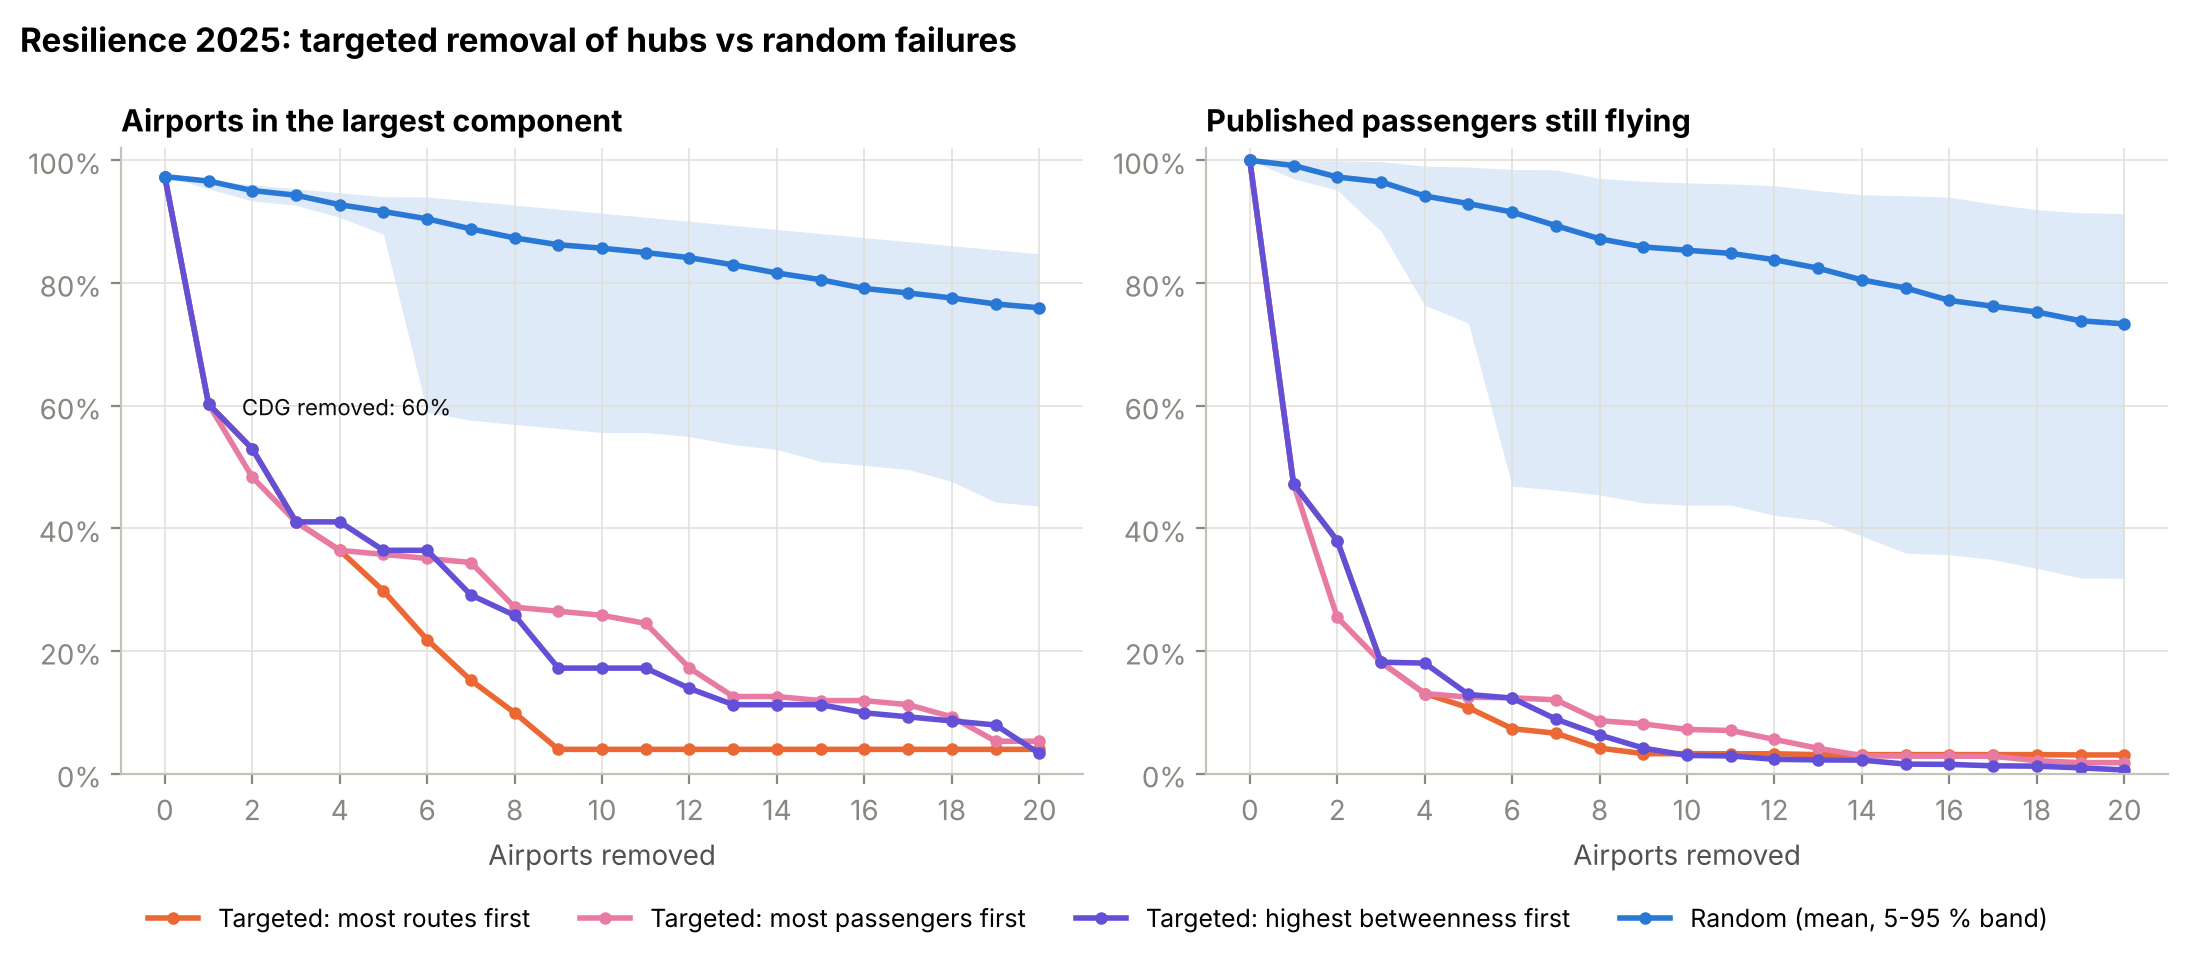

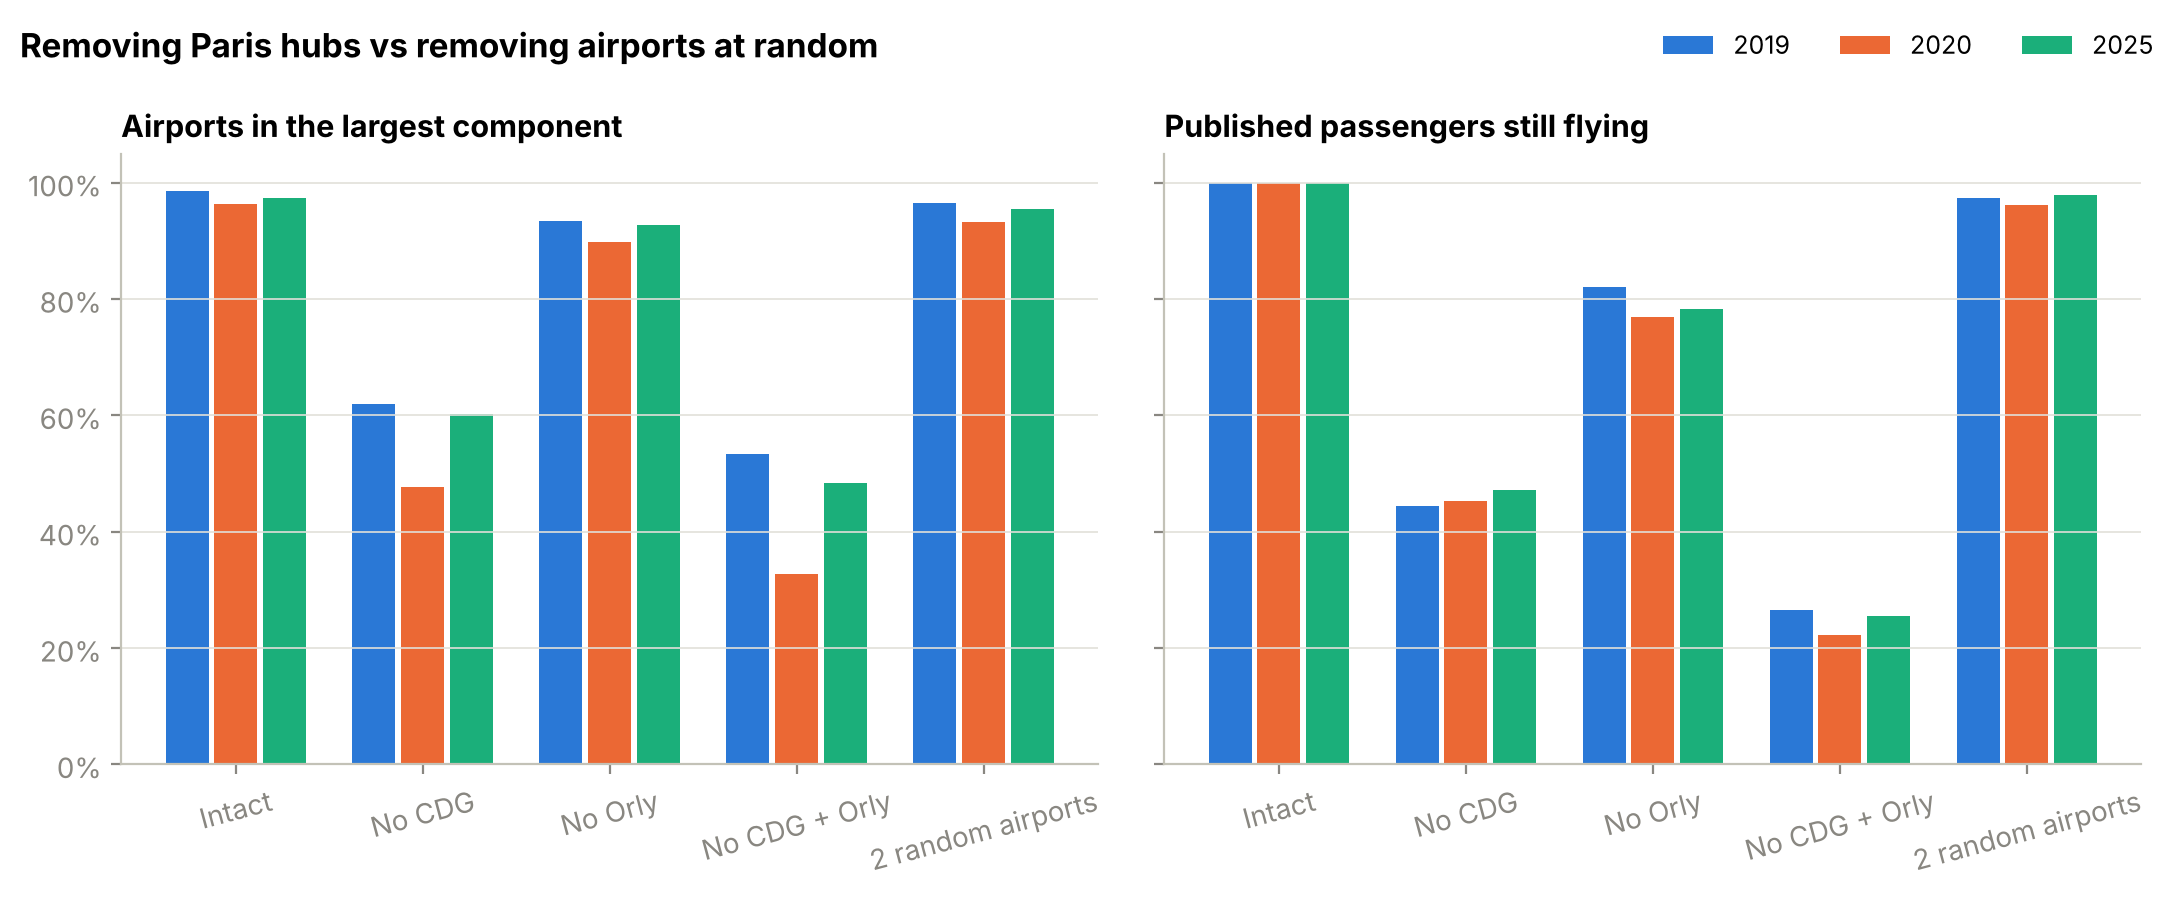

In [18]:
show('resilience_curves_2025')
show('resilience_scenarios')

Without CDG, the largest component falls to **60 %** of the airports, 49 airports are isolated and only **47 %** of the passengers keep their route; removing one airport at random leaves 96 % of the airports connected and 99 % of the passengers. Without CDG and Orly: 48 % of the airports and **25 %** of the passengers. Three targeted removals by degree halve the network, while after 20 random removals 76 % of the airports are still connected: the classic *robust-yet-fragile* signature of a hub-and-spoke network.

Caveat: the targeted orders above are computed once on the intact graph (static attack). `resilience.py` also runs an adaptive attack that recomputes betweenness after each removal (`betweenness_adaptive` in the table): after 10 removals the largest component falls to 3 %, against 17 % with the static betweenness order and 4 % with the static degree order. The static betweenness curve therefore understates the worst case; the static degree order comes close to it.

## 7. Communities

Louvain (`networkx.community.louvain_communities`, resolution 1, `seed=42`), weighted by passengers and unweighted, with modularity, stability over 20 seeds (adjusted Rand index) and the agreement between the two weightings.

In [19]:
import communities

comm_tab, comm_summary = communities.analyse(YEAR)
display(pd.DataFrame(comm_summary)[["weighted", "n_communities", "modularity", "cdg_orly_same",
                                    "ari_mean", "ari_min", "ari_weighted_vs_unweighted"]])
comm_tab[comm_tab["weighted"]][["community", "size", "metro", "overseas", "foreign",
                                "top_regions", "main_airports", "strength_share", "is_separate_component"]]

,weighted,n_communities,modularity,cdg_orly_same,ari_mean,ari_min,ari_weighted_vs_unweighted
0,True,8,0.363,False,0.914,0.813,0.4
1,False,8,0.398,False,0.950,0.840,0.4


,community,size,metro,overseas,foreign,top_regions,main_airports,strength_share,is_separate_component
0,0,76,1,0,75,"Northern Europe (26), Southern Europe & Mediterranean (17), United States (7)","PARIS-CHARLES DE GAULLE [LFPG], NEW YORK-KENNEDY [KJFK], MONTREAL-DORVAL [CY...",4.801e-01,False
1,1,36,5,5,26,"Southern Europe & Mediterranean (16), France (10), West Africa & Morocco (6)","PARIS-ORLY [LFPO], LYON-ST-EXUPERY [LFLL], MADRID-ADOLFO SUAREZ [LEMD], ROME...",3.234e-01,False
2,2,21,9,0,12,"France (9), Northern Europe (6), Southern Europe & Mediterranean (4)","NICE-COTE D'AZUR [LFMN], BALE-MULHOUSE [LFSB], BARCELONE-EL PRAT [LEBL], AMS...",1.400e-01,False
3,3,7,5,0,2,"France (5), West & North Africa (2)","ALGER [DAAG], MARSEILLE-PROVENCE [LFML], TUNIS [DTTA], AJACCIO-NAPOLEON-BONA...",4.627e-02,False
4,4,5,0,3,2,"France (3), South Pacific (1), United States (1)","TAHITI FAA'A [NTAA], BORA BORA [NTTB], RAIATEA [NTTR], AUCKLAND INTL [NZAA],...",6.767e-03,False
5,5,2,1,0,1,"France (1), Northern Europe (1)","FIGARI-SUD-CORSE [LFKF], BRUXELLES SUD-CHARLEROI [EBCI]",9.222e-04,False
6,6,2,1,0,1,"France (1), Southern Europe & Mediterranean (1)","BEAUVAIS-TILLE [LFOB], CHISINAU [LUKK]",9.105e-04,True
7,7,2,0,1,1,"Caribbean (1), France (1)","ST-BARTHELEMY [TFFJ], ST-MARTIN JULIANA [TNCM]",1.539e-03,True


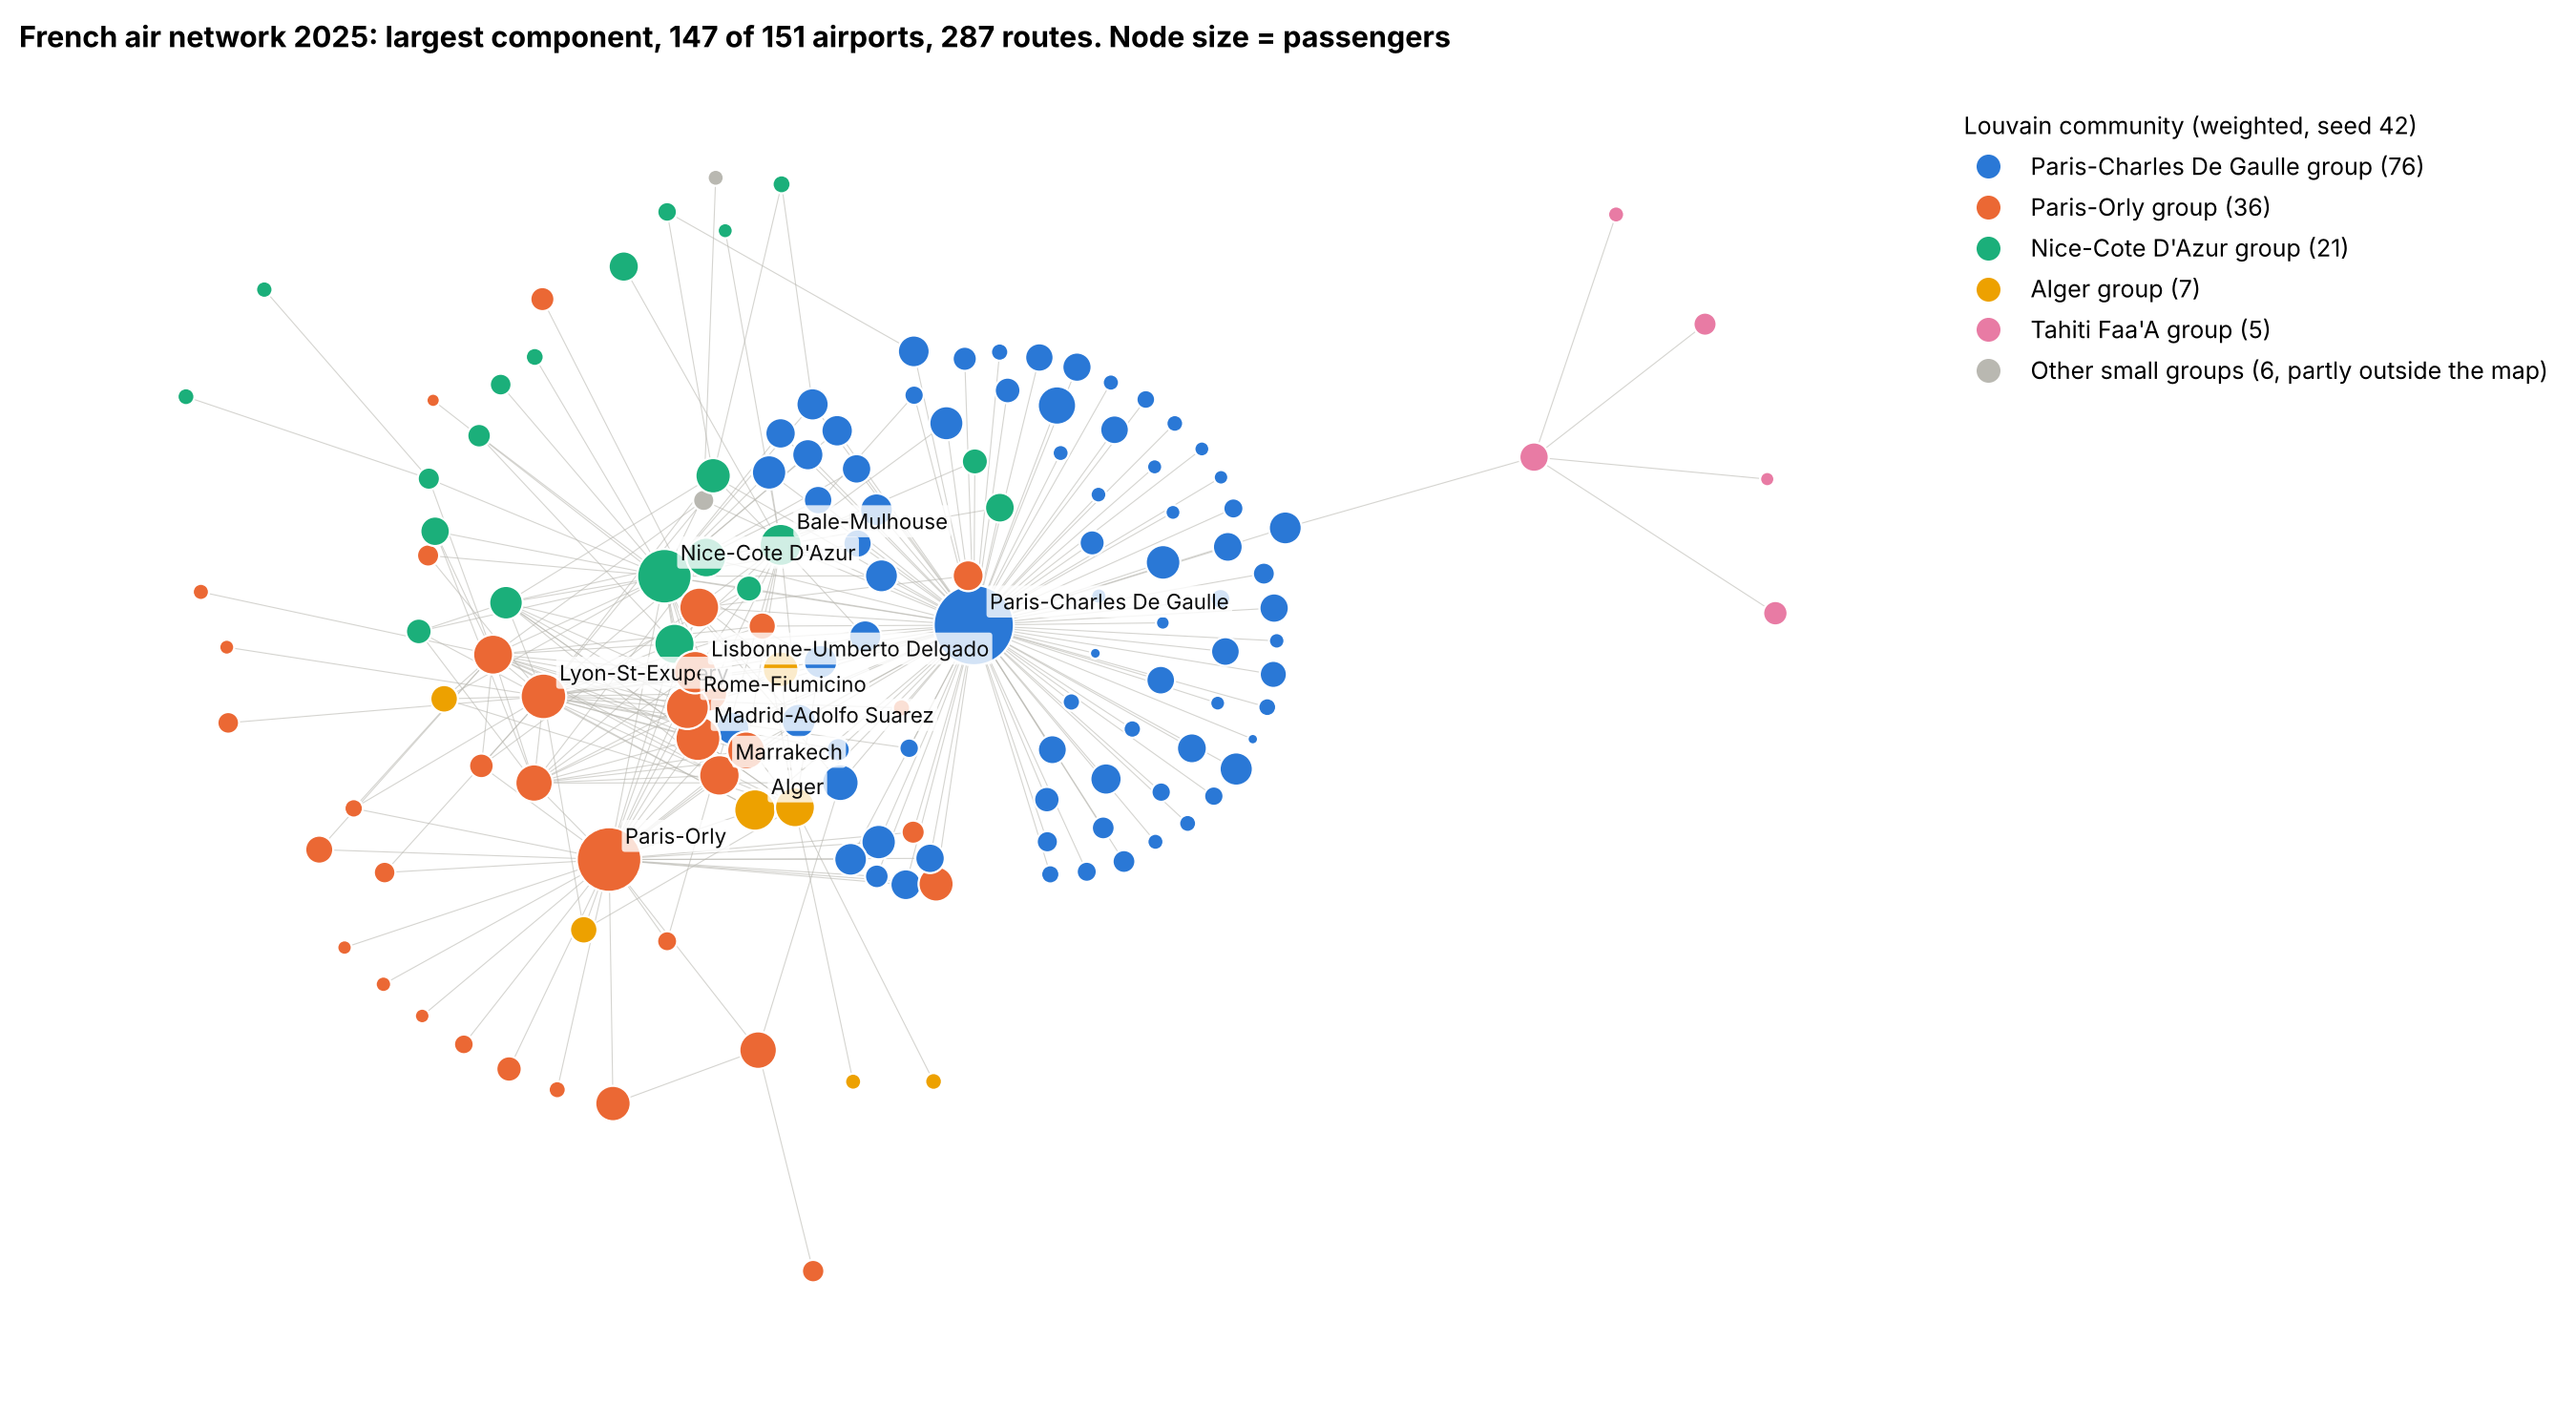

In [20]:
show('network_map_2025')

**Interpretation (2025, weighted by passengers; modularity 0.36).** The communities follow markets, not geography alone:

- **CDG's international network** (76 airports: CDG and 75 foreign airports, 48 % of the traffic): long-haul (New York, Montréal) and the European hubs. CDG is the only French airport in it: it is France's single gateway to most of the world.
- **Orly and Lyon** (36 airports, 32 %): domestic and overseas routes (Antilles, Réunion) plus Southern Europe, Portugal and Morocco, i.e. leisure and diaspora markets. CDG and Orly fall in different communities in all three years: the two Paris airports serve different markets rather than duplicating each other.
- **Nice and the regional airports** (21 airports, 14 %): Nice, Bâle-Mulhouse and other regional airports linked directly to European hubs and low-cost bases (Barcelona, Amsterdam, Gatwick), outside Paris.
- **Marseille - Corsica - Maghreb** (7 airports): Marseille, Ajaccio, Bastia with Algiers and Tunis, a Mediterranean corridor.
- **French Polynesia** (5 airports): Tahiti and the islands, connected to the world via San Francisco and Auckland.
- The remaining pairs (e.g. Saint-Barthélemy - Saint-Martin) are separate components or single routes, not real communities.

The partition is stable across seeds (mean ARI 0.91), but weighted and unweighted versions only partly agree (ARI 0.40): routes and traffic give different groupings, and we present the weighted one because it follows the flows.

## 8. Comparison over time

In [21]:
import comparison

graphs = build_graphs(comparison.YEARS)
years = comparison.year_table(graphs)
years[["nodes", "edges", "passengers_m", "components", "lcc_diameter", "cdg_route_share",
       "cdg_passenger_share", "paris_passenger_share", "effective_airports", "betweenness_CDG",
       "n_communities", "modularity", "lcc_share_without_cdg", "passengers_kept_without_cdg"]].T

year,2019,2020,2025
nodes,137.000,107.000,151.000
edges,293.000,183.000,289.000
passengers_m,78.430,18.016,73.577
components,2.000,3.000,3.000
lcc_diameter,5.000,4.000,6.000
cdg_route_share,0.358,0.437,0.343
cdg_passenger_share,0.556,0.547,0.527
paris_passenger_share,0.735,0.777,0.745
effective_airports,10.518,10.220,11.064
betweenness_CDG,0.736,0.780,0.708


,from,to,kept,lost,gained,jaccard,note
0,2019,2020,162,131,21.0,0.516,NaN
1,2019,2025,193,100,96.0,0.496,NaN
2,2020,2025,145,38,144.0,0.443,NaN
3,2019,2025,57,74,NaN,NaN,routes lost in 2020: back in 2025 (kept) / still missing (lost)


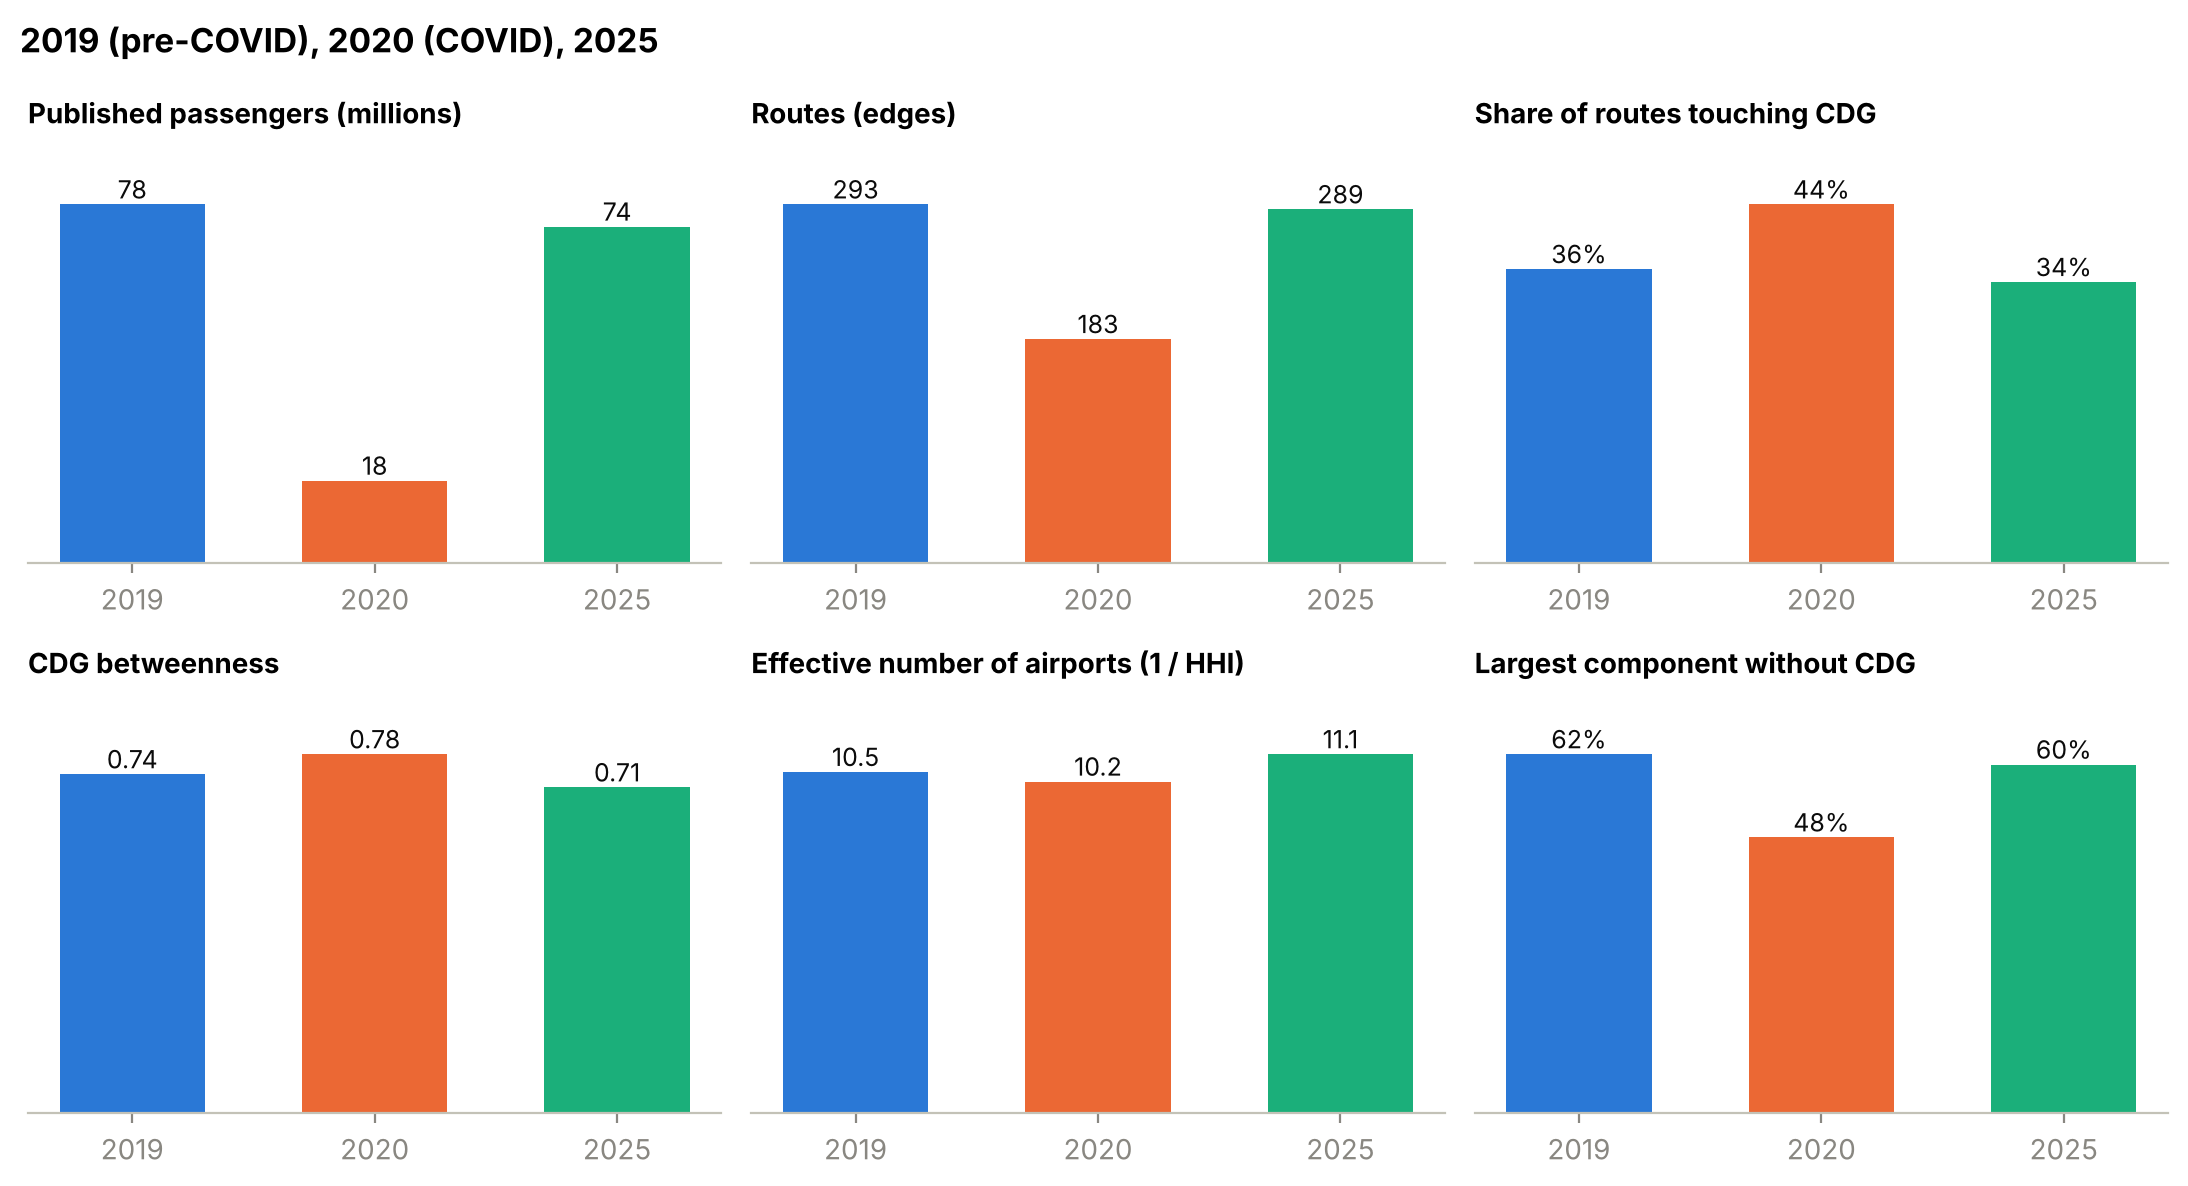

In [22]:
display(comparison.route_turnover(graphs))
show('comparison_years')

,nodes,edges,passengers_m,cdg_degree_share,cdg_betweenness,cdg_passenger_share
year,,,,,,
1990,98,127,24.035,0.588,0.695,0.574
2000,126,176,45.991,0.736,0.819,0.624
2002,114,159,39.561,0.788,0.856,0.729
2010,133,198,47.171,0.750,0.774,0.651
2019,137,293,78.430,0.772,0.736,0.556
2020,107,183,18.016,0.755,0.780,0.547
2021,117,205,23.985,0.741,0.741,0.487
2025,151,289,73.577,0.660,0.708,0.527


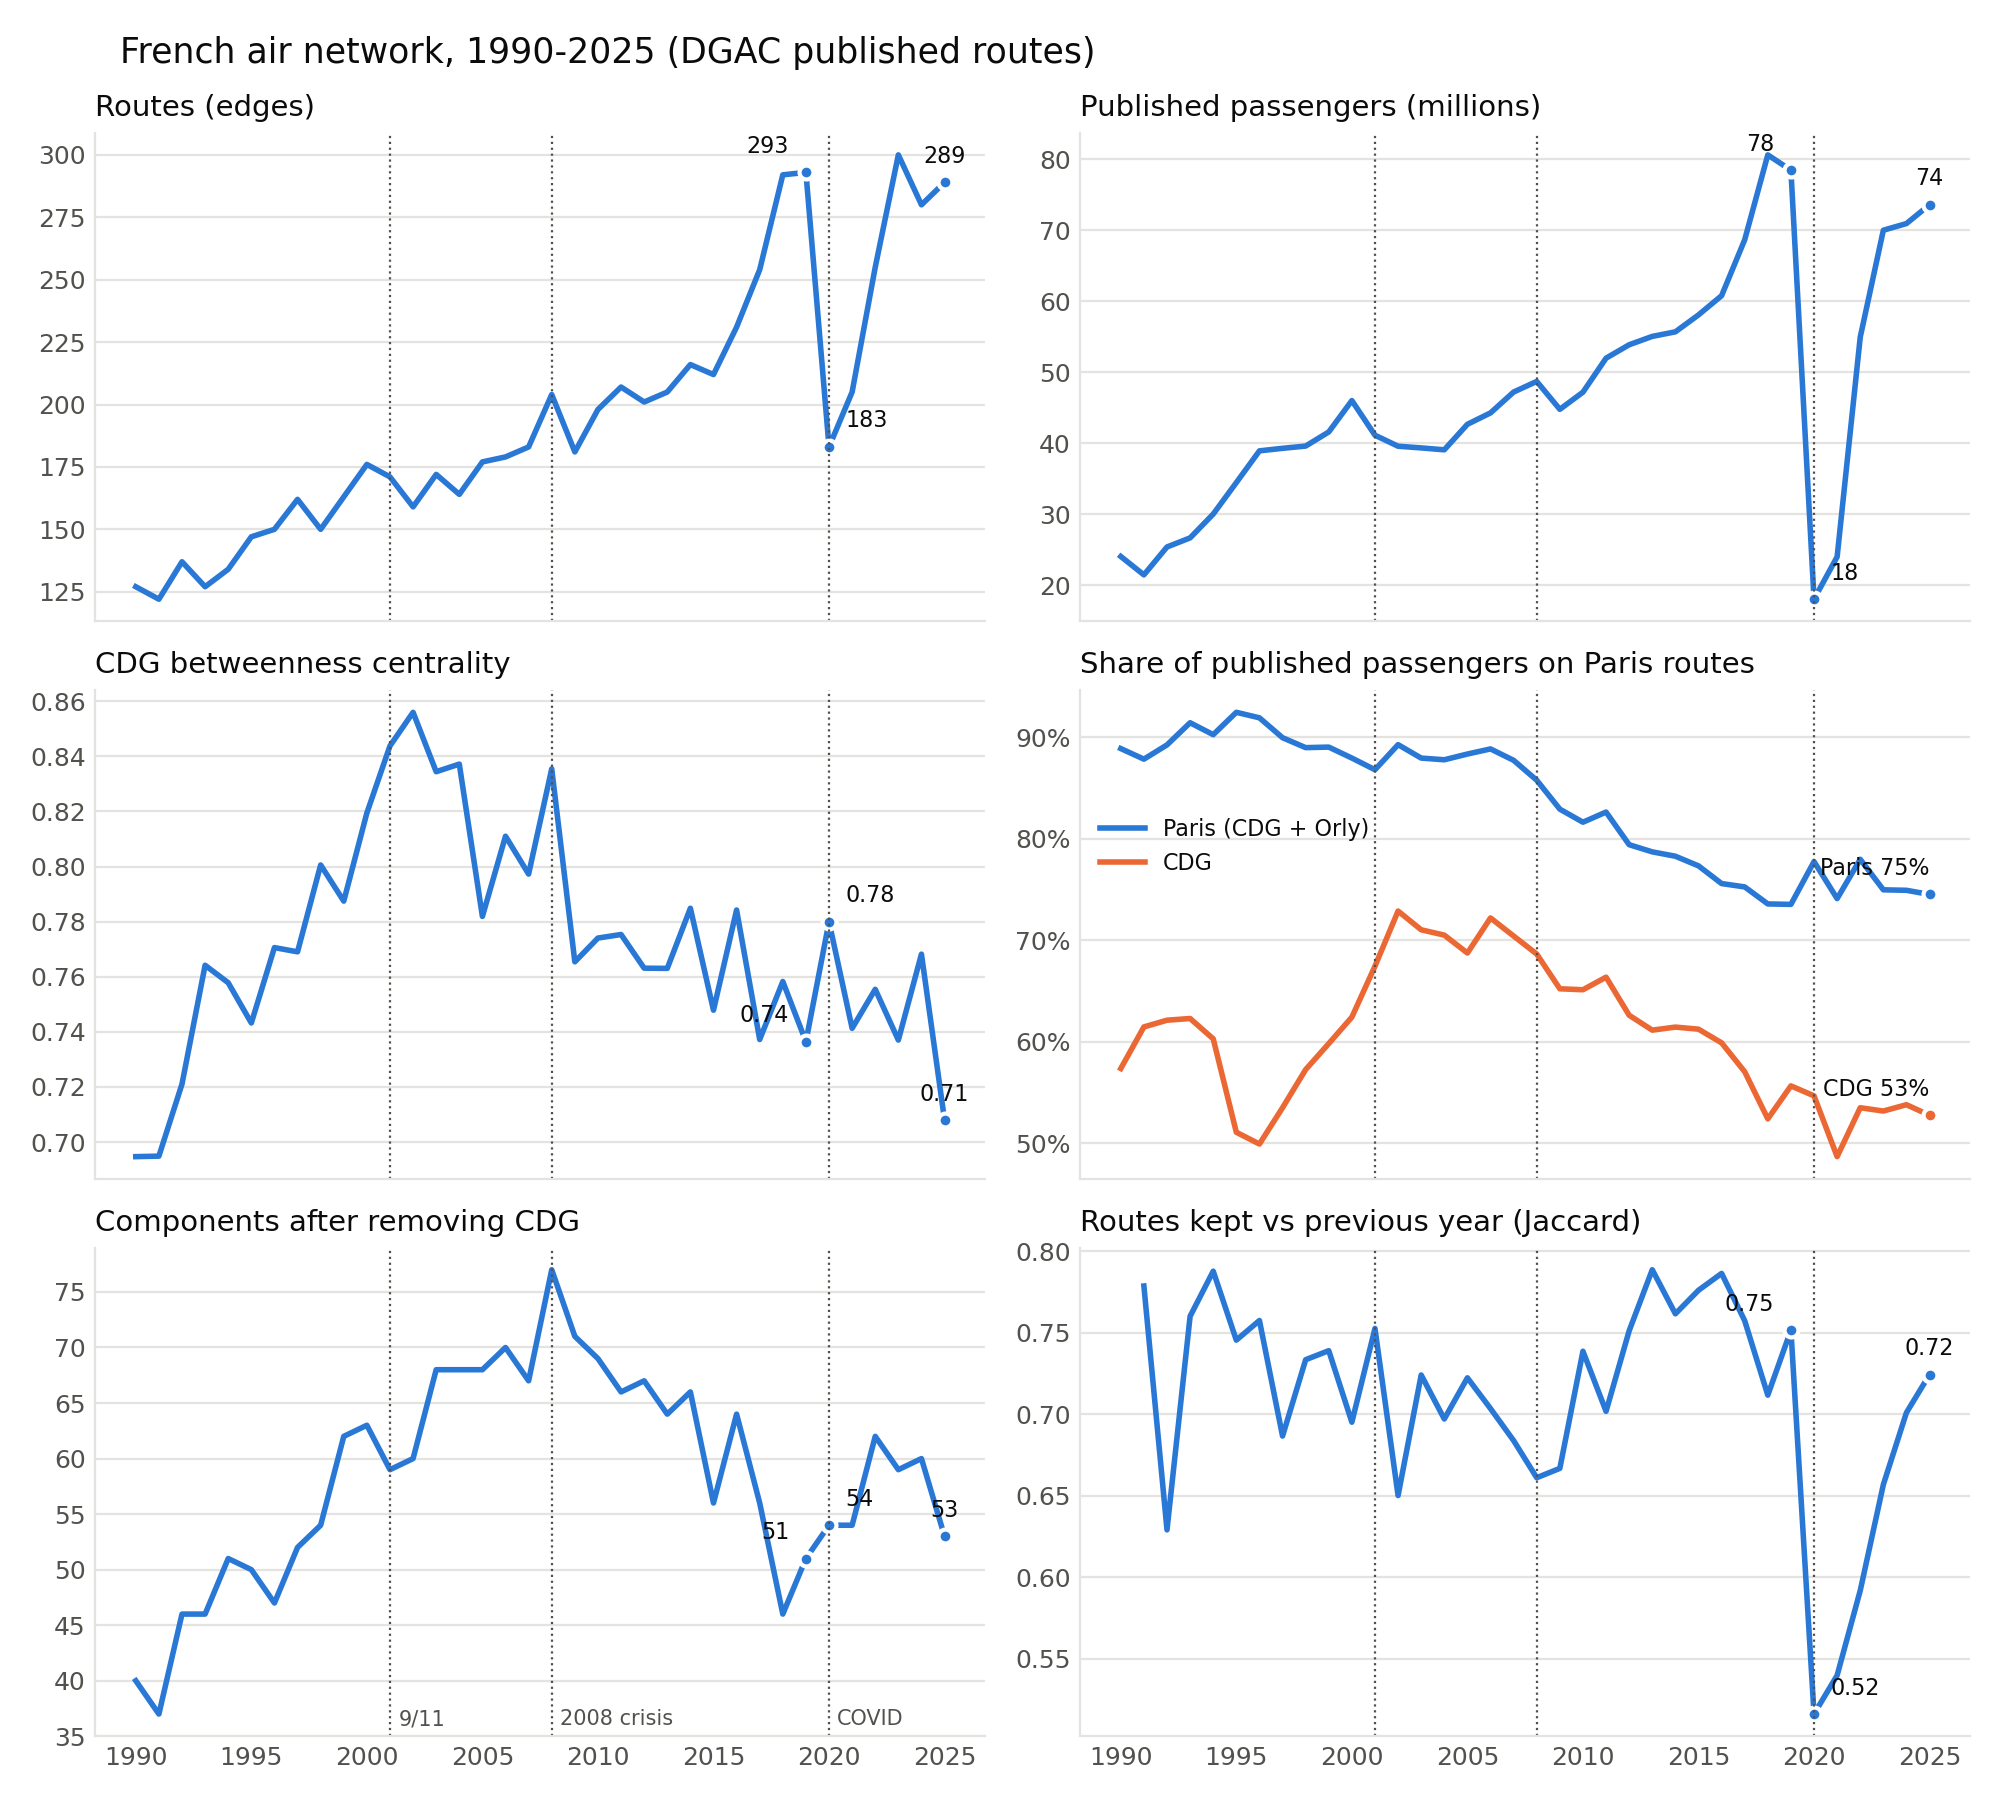

In [23]:
import time_series

ts = time_series.run()
display(ts.loc[[1990, 2000, 2002, 2010, 2019, 2020, 2021, 2025],
               ["nodes", "edges", "passengers_m", "cdg_degree_share", "cdg_betweenness", "cdg_passenger_share"]])
show('time_series')

Published passengers went from 78.4 M (2019) to 18.0 M (2020) and 73.6 M (2025): **not fully recovered** (-6 %). COVID briefly made the network *more* dependent on CDG (betweenness 0.74 -> 0.78), and 2025 is the least CDG-dependent of the three years (0.71), with more airports and a more spread-out traffic (more "effective airports"). Of the 131 routes lost in 2020, 57 are published again in 2025 and 74 are still missing. Caveat: part of these changes come from the publication rule (a route disappears when it falls below the threshold or loses competitors), not only from real traffic.

Over 1990-2025, CDG's betweenness stays between 0.69 (1990) and 0.86 (2002), above 0.80 in 1998 and in most years from 2000 to 2008: **the centralisation on CDG is a structural constant**, with a peak in the early 2000s.

## 9. Robustness of the conclusions and limitations

In [24]:
import filter_sensitivity

sens = filter_sensitivity.run(YEAR)
sens[["view", "variant", "nodes", "edges", "top_airport", "cdg_betweenness", "orly_rank", "spearman_vs_baseline"]]

,view,variant,nodes,edges,top_airport,cdg_betweenness,orly_rank,spearman_vs_baseline
0,full network,baseline (all published routes),151,289,LFPG,0.708,3,1.000
1,full network,>= 50k passengers,110,191,LFPG,0.690,2,0.830
2,full network,>= 100k passengers,96,151,LFPG,0.724,2,0.795
3,full network,>= 250k passengers,72,92,LFPG,0.844,2,0.675
4,full network,>= 500k passengers,46,49,LFPG,0.828,2,0.551
5,full network,>= 6 months published,97,151,LFPG,0.688,2,0.802
6,full network,12 months published,66,77,LFPG,0.837,2,0.649
7,domestic,baseline (all published routes),25,40,LFPO,0.103,1,1.000
8,domestic,>= 50k passengers,21,28,LFPO,0.075,1,0.901
9,domestic,>= 100k passengers,21,24,LFMN,0.121,2,0.838


Whatever the passenger or seasonality threshold, CDG stays the top airport of the full network (betweenness 0.69 to 0.84). Orly is the top domestic airport under every threshold except >= 100k passengers, where Nice comes first and Orly second: the international conclusions do not depend on the filtering choices, the domestic ranking is less stable.

**Limitations**
- DGAC publication rule: routes with fewer than 3 airlines or one dominant airline are missing; no foreign-foreign routes.
- **Incomplete domestic network**: the published routes cover only part of each airport's real traffic (coverage = passengers on published routes / airport passengers: CDG 54 %, Orly 46 %, Toulouse 21 %, Bordeaux 17 %). The domestic network has only 40 routes, and major single-airline routes such as Lyon-CDG, Toulouse-CDG or Marseille-Orly are missing (Bordeaux-Orly is absent because it closed in 2021, not because of the filter). Section 4b checks the domestic results against the complete Eurostat data (2024): the decentralisation holds, but Paris has two domestic hubs (Orly by passengers, CDG by routes) rather than one. Eurostat has no 2025 data yet and does not cover routes between two small non-reporting airports.
- **Cargo routes in a passenger graph**: a few published routes carry (almost) no passengers. They are cargo flights to the DHL / UPS hubs (Leipzig, Liège, Cologne): 6 routes with 0 passengers across 2019 and 2020, and in 2025 CDG-Dubai World Central (14 passengers) and CDG-Cologne (131 passengers). They count in the number of routes and in CDG's degree (99 instead of 97); the effect on the results is small.
- Annual, undirected graph: no direction, frequency or seasonality inside a year; no airline or alliance information (hub strategies of individual carriers are not visible).
- Distances in hops, not km or travel time; no connection times.
- The main resilience curves use static attack orders (the adaptive betweenness attack is more damaging, see section 6), and remove whole airports, not single routes.
- Louvain is randomised: results are given for `seed=42` with a stability check; small differences can appear between NetworkX versions.

## 10. Conclusion

1. **Centralised**: CDG concentrates a third of the routes, more than half of the passengers and a betweenness five times that of the next airport, and it is the only gateway to 49 foreign destinations. This is an international phenomenon: the complete domestic network (Eurostat, 2024) is decentralised, with two Paris hubs, Orly by passengers and CDG by routes.
2. **Fragile**: robust to random failures, but losing CDG disconnects 40 % of the airports and half of the traffic; losing CDG and Orly leaves a quarter of the traffic.
3. **Stable**: the dependence on CDG is what its number of routes implies (null model), it has lasted 35 years, and COVID only reinforced it temporarily.

## Appendix A. Exploratory: two definitions of passengers lost

`passengers_kept` counts every route that still flies; `passengers_connected` only counts routes in the largest component. Same attack orders and seeds as section 6.

,year,scenario,passengers_kept,passengers_connected,gap
0,2025,none,1.000,0.998,0.002
1,2025,CDG,0.473,0.463,0.010
2,2025,Orly,0.782,0.780,0.002
3,2025,CDG + Orly,0.255,0.233,0.022


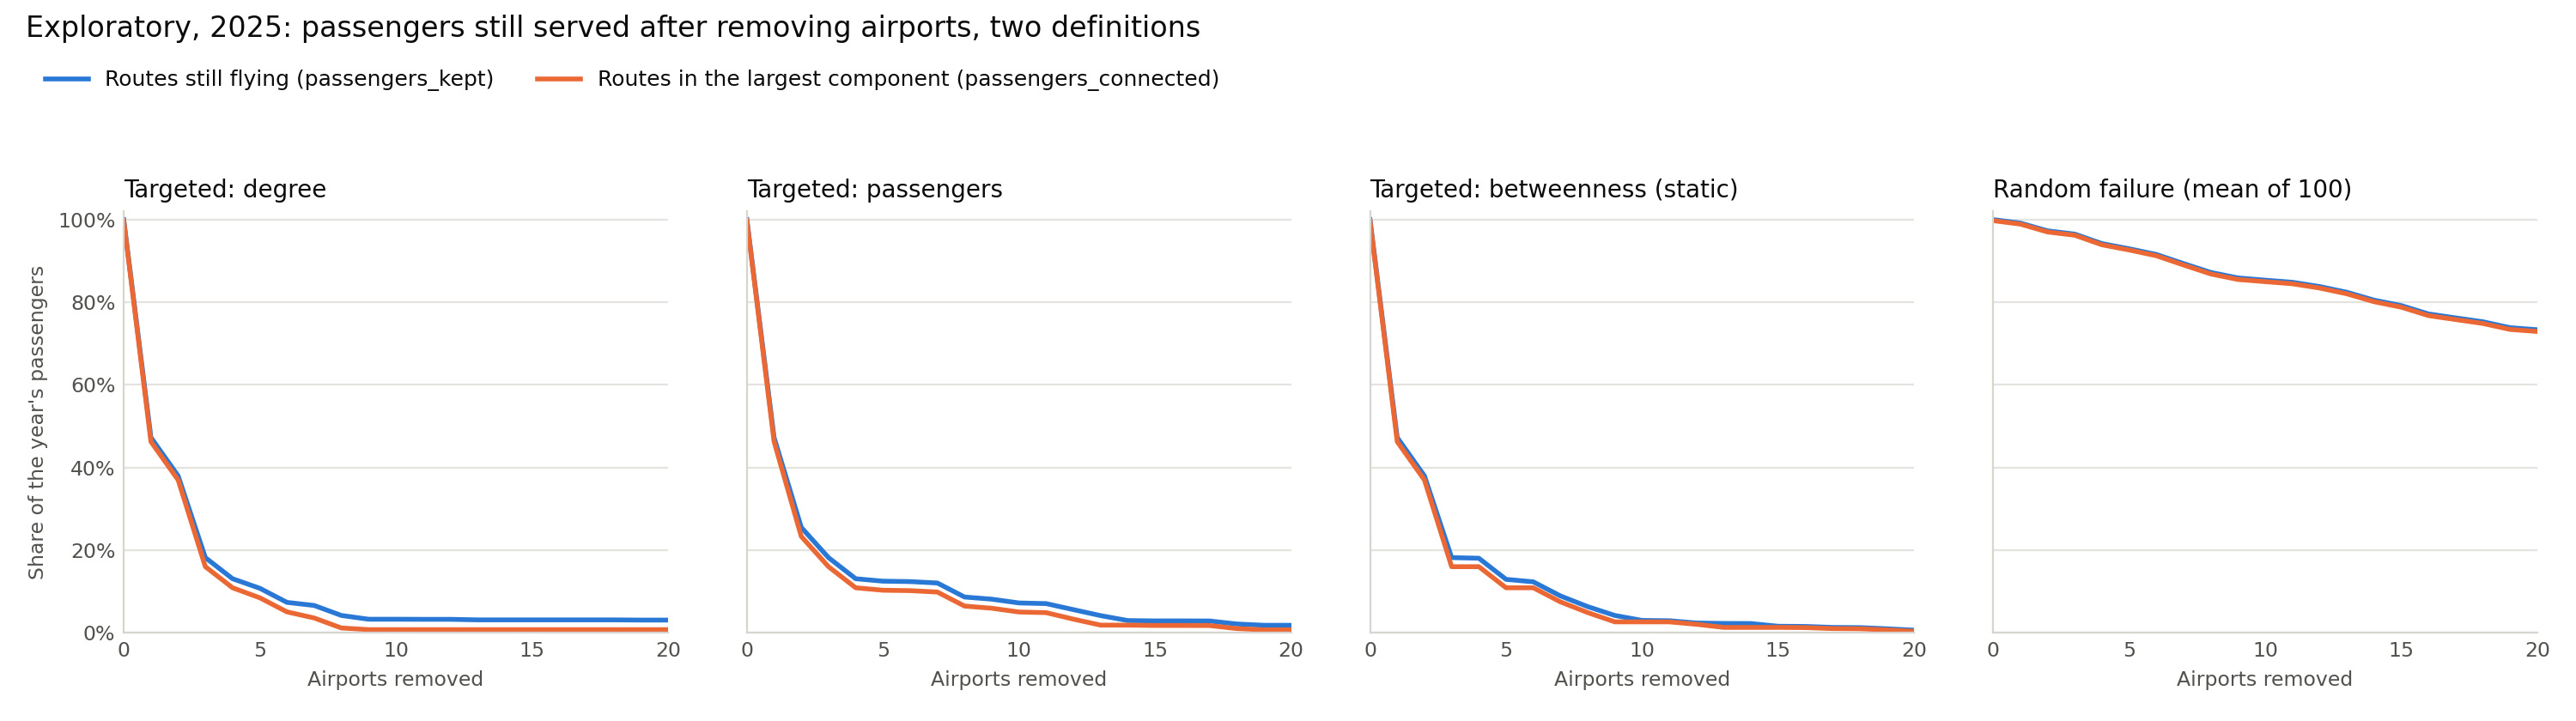

In [25]:
import passenger_metrics

display(passenger_metrics.scenarios(G))
show('passenger_metrics_2025')

The two definitions differ by at most 2.5 points: the conclusions of section 6 do not depend on the choice.

## Appendix B. Explored and rejected: bipartite projection

French airports projected through their shared foreign destinations, with Louvain on the projection.

In [26]:
import bipartite_projection

bipartite_projection.run(YEAR)[0].drop(columns="largest_community")

,year,variant,nodes,edges,density,components,communities,community_sizes,largest_community_share,modularity
0,2025,"shared, with Paris",21,68,0.324,4,5,"[16, 2, 1, 1, 1]",0.76,0.006
1,2025,"shared, without Paris",19,44,0.257,6,8,"[10, 2, 2, 1, 1, 1, 1, 1]",0.53,0.021
2,2025,"jaccard, with Paris",21,68,0.324,4,6,"[14, 2, 2, 1, 1, 1]",0.67,0.211
3,2025,"jaccard, without Paris",19,44,0.257,6,8,"[10, 2, 2, 1, 1, 1, 1, 1]",0.53,0.264


Modularity stays close to 0 with shared-destination weights (and low with Jaccard weights): French airports do not split into distinct international markets, they mostly serve the same European hubs. The option was dropped in favour of Louvain on the full graph (section 7).

In [27]:
if REGENERATE_FIGURES:
    import figures, network_map
    figures.main(YEAR)
    coords, rings = network_map.load_coords(), network_map.load_countries()
    network_map.map_full(G, coords, rings, RESULTS / f"map_full_{YEAR}.png")
    network_map.map_french(G, coords, rings, RESULTS / f"map_french_{YEAR}.png")
    null_model.plot(null_table, null_samples, RESULTS / f"null_model_{YEAR}.png")
    time_series.plot(ts, RESULTS / "time_series.png")
    passenger_metrics.plot(passenger_metrics.curves(G).assign(year=YEAR), YEAR,
                           RESULTS / f"passenger_metrics_{YEAR}.png")